# Trustworthy Explainable AI for Diabetic-Retinopathy Grading — APTOS-2019

**A joint faithfulness + sanity benchmark for transformer-based DR grading.**

This notebook evaluates five attribution methods on a vision-transformer DR grader across
**two complementary trustworthiness axes**:

| Axis | Question it answers | Ground truth needed |
|---|---|---|
| **Faithfulness** | Does the attribution reflect what the model actually used? | none |
| **Sanity** | Does the attribution depend on the model at all? | none |
| ~~Plausibility~~ | ~~Does the attribution land on actual pathology?~~ | **pixel masks — APTOS has none** |

> ### Why this run is two-axis, not three
> APTOS-2019 ships image-level severity labels only. It contains **no pixel-level lesion
> annotation of any kind**, so the plausibility axis is not computable here — not as a
> limitation of this study, but by construction of the dataset. Plausibility is reported
> for IDRiD only (n=81 segmentation images), and that **asymmetry must be stated explicitly**
> in the manuscript rather than left for a reviewer to notice.

### Data provenance
- **Source**: APTOS-2019 Blindness Detection, 3,662 labelled fundus images.
- **Split**: stratified **70/15/15** → **2,930 train / 366 val / 366 test** unique retinas.
  APTOS has no official test partition (Kaggle withheld the competition test labels), so all
  three splits were created here. This differs from IDRiD, where the official 103-image test
  set was preserved for literature comparability — a deliberate, dataset-dependent choice.
- **Preprocessing**: retinal ROI crop → resize 224 → CLAHE on **all** splits → geometric
  augmentation **train only** (per-class floor of 600), giving 4,042 training images from
  2,930 unique retinas.
- **Leakage**: verified — zero image-ID overlap between train, validation and test.

### Honest-reporting notes
- Report **2,930 unique training retinas**, not the 4,042 augmented total.
- The APTOS balancing policy (floor of 600) differs from the rebuilt IDRiD policy
  (60% of majority, 4× cap). Both are stated in Methods; the datasets differ ~7× in size.
- Attention-Rollout is ViT-only; Swin substitutes a labelled **TokenNorm surrogate**.


## 0 · Environment & reproducibility

In [1]:
# ---------------------------------------------------------------
# DEPENDENCIES
# ---------------------------------------------------------------
# timm: Swin/ViT backbones | captum: Integrated Gradients & attributions
# scikit-image: blurring baseline & morphology for masks
!pip install -q timm captum scikit-image scikit-learn seaborn tqdm gdown rarfile

import os, sys, json, math, random, warnings, logging
from typing import Optional, Dict, List, Callable
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings("ignore", category=UserWarning)

# ---------------------------------------------------------------
# LOGGING — prefer logging over bare prints for pipeline stages
# ---------------------------------------------------------------
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)-7s | %(message)s",
    datefmt="%H:%M:%S",
)
log = logging.getLogger("dr_xai")

# ---------------------------------------------------------------
# GLOBAL REPRODUCIBILITY
# ---------------------------------------------------------------
def set_seed(seed: int = 42) -> None:
    """Seed all RNGs and force deterministic cuDNN.

    We trade convolution-autotuning speed for reproducibility on purpose:
    ``benchmark=False`` + ``deterministic=True`` make results repeatable for
    the thesis/methods section (see the markdown note above).
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False       # was True -> nondeterministic
    torch.backends.cudnn.deterministic = True    # reproducible convolutions

SEED = 42
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
log.info("Device: %s | torch %s", device, torch.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 28.1 MB/s eta 0:00:00


## 1 · Configuration

One config object drives the whole notebook. **`MODEL_NAME` is the only line to change**
for the ViT variant — every downstream cell is architecture-aware via `IS_VIT`.

In [2]:
# ---------------------------------------------------------------
# CONFIG — SINGLE SOURCE OF TRUTH for the whole notebook.
# Merged: rebuilt-pipeline paths + every field the explainer/faithfulness/
# sanity cells reference. Do not define CFG anywhere else.
# ---------------------------------------------------------------
from dataclasses import dataclass, field
from typing import List, Tuple
import json, os

@dataclass
class CFG:
    # --- data (rebuilt pipeline) ---
    BASE_DIR: str          = "/content/APTOS2019_classfolders_Cropped_224_Aug_CLAHE"
    META_DIR: str          = "/content/drive/MyDrive/11_07_2026_APTOS_2019_Dataset/_meta"
    DATASET_NAME: str      = "APTOS"
    IMG_SIZE: int          = 224
    NUM_CLASSES: int       = 5
    NUM_WORKERS: int       = 2
    DATA_PREPROCESSED: bool = True      # crop / CLAHE / augmentation done offline

    # --- lesion masks: NOT AVAILABLE for APTOS (no pixel annotation exists) ---
    LESION_MASK_DIR: str   = ""
    MASK_SUFFIX: str       = ""

    # --- model:  CHANGE THIS LINE ONLY for the ViT variant ---
    MODEL_NAME: str        = "swin_tiny_patch4_window7_224"
    # ViT variant:         "vit_base_patch16_224"
    PRETRAINED: bool       = True
    DROP_RATE: float       = 0.15     # 0.3 under-fit; model stalled at train_acc 0.87
    DROP_PATH_RATE: float  = 0.1      # keep mild stochastic depth

    # --- training ---
    EPOCHS: int            = 60       # allow a later peak
    HEAD_ONLY_EPOCHS: int  = 5        # longer warm-up before unfreezing          # warm-up before unfreezing the backbone
    BATCH_SIZE: int        = 32       # APTOS is ~8x larger than IDRiD
    LR: float              = 3e-5       # alias used by the training cell
    LR_HEAD: float         = 1e-3       # phase 1 (head only)
    LR_FINETUNE: float     = 2e-5     # between the two runs
    WEIGHT_DECAY: float    = 0.01     # 0.05 was too strong for 371 retinas
    LABEL_SMOOTH: float    = 0.05
    LABEL_SMOOTHING: float = 0.05       # alias for inherited cells
    PATIENCE: int          = 15       # val QWK is noisy on 42 images
    USE_CLASS_WEIGHTS: bool = True
    WEIGHT_POWER: float    = 0.75     # temper inverse-freq weights (0=off, 1=full)
    CLASS1_BOOST: float    = 1.6      # extra weight: Class 1 scored 0.0000 (never predicted)

    # --- ordinal-aware loss ---
    # DR grades are ORDERED and QWK penalises distant errors quadratically, but
    # plain cross-entropy treats grade0-vs-4 the same as grade0-vs-1. A soft
    # ordinal penalty adds |pred - true| distance cost, aligning the objective
    # with the reported metric.
    USE_ORDINAL_LOSS: bool = True
    ORDINAL_LAMBDA: float  = 0.3      # weight of the ordinal term

    # --- XAI evaluation ---
    XAI_N_PER_CLASS: int   = 12       # 60 images/seed; APTOS has ample test data
    DELINS_STEPS: int      = 50
    IG_STEPS: int          = 32
    BLUR_SIGMA: float      = 8.0        # blurred perturbation baseline
    SANITY_N: int          = 30
    SANITY_N_IMAGES: int   = 30         # alias for inherited cells
    SANITY_FRACS: Tuple    = (0.25, 0.50, 1.00)

    # --- normalisation placeholders (overwritten from TRAIN split in section 3) ---
    MEAN: Tuple            = (0.485, 0.456, 0.406)
    STD: Tuple             = (0.229, 0.224, 0.225)

    # --- reproducibility ---
    SEED: int              = 42
    SEEDS_FOR_VARIANCE: Tuple = (42, 1, 7)

    # --- output ---
    OUT_DIR: str           = "/content/outputs"
    CKPT: str              = "best_model.pt"

cfg = CFG()
SEED = cfg.SEED                          # some inherited cells use a bare SEED
os.makedirs(cfg.OUT_DIR, exist_ok=True)

IS_VIT = "vit" in cfg.MODEL_NAME.lower()
ARCH_TAG = "ViT-B16" if IS_VIT else "Swin-T"
RUN_TAG = f"{ARCH_TAG}_{cfg.DATASET_NAME}"

set_seed(cfg.SEED)
log.info("RUN: %s | backbone=%s | IS_VIT=%s", RUN_TAG, cfg.MODEL_NAME, IS_VIT)

# NOTE: class weights are computed in section 3, AFTER the datasets exist.
# They are derived from the actual post-augmentation training counts rather
# than a metadata file, so a lost/absent class_weights.json cannot break the run.
CLASS_WEIGHTS = None
class_weights = None

In [3]:
# ---------------------------------------------------------------
# (Config intentionally REMOVED from this cell.)
# A duplicate CFG here would silently overwrite the merged config in
# section 2 and drop fields the explainer cells need (this caused an
# AttributeError on cfg.BLUR_SIGMA). The single source of truth is
# section 2 · Configuration.
# ---------------------------------------------------------------
log.info('config defined in section 2 (single source of truth)')

In [4]:
# ---------------------------------------------------------------
# PUBLICATION FIGURE STYLE  —  single source of truth for ALL figures.
# Set once here; every figure below inherits it, so font sizes, weights,
# and DPI are IDENTICAL across the whole paper. To restyle every figure,
# change these values in ONE place (e.g. flip weight to "normal" for a
# lighter journal-classic look).
# ---------------------------------------------------------------
import matplotlib as mpl
import matplotlib.pyplot as plt

PUB = dict(
    base_fs  = 12,      # base font size
    title_fs = 13,      # axes titles
    label_fs = 12,      # x / y axis labels
    tick_fs  = 11,      # tick numbers
    annot_fs = 11,      # in-figure annotations / heatmap cell numbers / point labels
    weight   = "bold",  # uniform text weight -> no faded or thin labels anywhere
    save_dpi = 300,     # 300 dpi = print quality expected by a Q1 journal
)

mpl.rcParams.update({
    "figure.dpi":        110,               # crisp inline preview
    "savefig.dpi":       PUB["save_dpi"],   # high-res files for the manuscript
    "savefig.bbox":      "tight",           # never clip labels / legends on save
    "savefig.facecolor": "white",           # white bg (not transparent) for Word / print
    "figure.facecolor":  "white",
    "font.family":       "sans-serif",
    "font.sans-serif":   ["DejaVu Sans", "Arial", "Helvetica"],
    "font.size":         PUB["base_fs"],
    "font.weight":       PUB["weight"],      # bolds ticks, legend and annotations too
    "axes.titlesize":    PUB["title_fs"],
    "axes.titleweight":  PUB["weight"],
    "axes.labelsize":    PUB["label_fs"],
    "axes.labelweight":  PUB["weight"],
    "xtick.labelsize":   PUB["tick_fs"],
    "ytick.labelsize":   PUB["tick_fs"],
    "legend.fontsize":   PUB["tick_fs"],
    "legend.title_fontsize": PUB["tick_fs"],
    "axes.linewidth":    1.2,                # slightly heavier frame reads cleaner in print
    "axes.edgecolor":    "black",
    "axes.grid":         False,
    "lines.linewidth":   2.0,
})

def save_fig(fig, name):
    """Save a figure to OUT_DIR at publication DPI, never clipping labels."""
    path = os.path.join(cfg.OUT_DIR, name)
    fig.savefig(path, dpi=PUB["save_dpi"], bbox_inches="tight", facecolor="white")
    return path

log.info("Publication figure style applied (weight=%s, save_dpi=%d).",
         PUB["weight"], PUB["save_dpi"])


## 2 · Restore the dataset

One archive: the already-preprocessed APTOS class-folder tree. Unlike the IDRiD notebooks
there is no second (plausibility) archive, because APTOS has no lesion masks.

In [5]:
# ---------------------------------------------------------------
# RESTORE FROM DRIVE — survives Colab runtime restarts
# ---------------------------------------------------------------
from google.colab import drive
import os, zipfile

if not os.path.ismount("/content/drive"):
    drive.mount("/content/drive")

DRIVE_ROOT = "/content/drive/MyDrive/11_07_2026_APTOS_2019_Dataset"
ARCHIVE = os.path.join(DRIVE_ROOT,
                       "APTOS2019_classfolders_Cropped_224_Aug_CLAHE.zip")

if not os.path.isfile(ARCHIVE):
    # tolerate a slightly different filename without forcing a manual edit
    import glob
    cands = glob.glob(os.path.join(DRIVE_ROOT, "*Aug*CLAHE*.zip"))
    if not cands:
        raise FileNotFoundError(
            f"Preprocessed APTOS archive not found in {DRIVE_ROOT}\n"
            f"  -> !ls '{DRIVE_ROOT}' and set ARCHIVE explicitly.")
    ARCHIVE = cands[0]
    log.warning("Using discovered archive: %s", os.path.basename(ARCHIVE))

log.info("archive: %s (%.1f MB)", os.path.basename(ARCHIVE),
         os.path.getsize(ARCHIVE) / 1e6)

if not os.path.isdir(cfg.BASE_DIR):
    with zipfile.ZipFile(ARCHIVE) as z:
        z.extractall("/content/")
    log.info("extracted -> /content/")
else:
    log.info("already extracted, skipping.")

os.makedirs(cfg.META_DIR, exist_ok=True)
log.info("metadata dir: %s", cfg.META_DIR)

Mounted at /content/drive


In [6]:
# ---------------------------------------------------------------
# VERIFY the restored tree before training touches anything.
#
# NOTE ON FOLDER NAMES: this archive uses "validation" and capitalised
# "Class0..Class4", whereas the IDRiD pipeline used "val" and "class0..4".
# Rather than rename thousands of files, the loader below maps the names.
# ---------------------------------------------------------------
from pathlib import Path
import pandas as pd

SPLIT_DIRS = {"train": "train", "val": "validation", "test": "test"}
CLASS_DIRS = {k: f"Class{k}" for k in range(5)}

_base = Path(cfg.BASE_DIR)
if not _base.is_dir():
    raise FileNotFoundError(f"{cfg.BASE_DIR} not found after extraction.")

rows = []
for sp, sp_dir in SPLIT_DIRS.items():
    for k, cls_dir in CLASS_DIRS.items():
        d = _base / sp_dir / cls_dir
        rows.append({"split": sp, "class": f"class{k}",
                     "n": len(list(d.glob("*.png"))) + len(list(d.glob("*.jpg")))
                          if d.is_dir() else 0})
piv = (pd.DataFrame(rows).pivot(index="split", columns="class", values="n")
         .reindex(["train", "val", "test"]))
piv["TOTAL"] = piv.sum(axis=1)
print("Restored APTOS data:")
print(piv.to_string())

_tot = int(piv["TOTAL"].sum())
print(f"\nTotal images: {_tot}")
assert _tot > 0, "No images found — check the archive structure."
for sp in ["train", "val", "test"]:
    assert int(piv.loc[sp, "TOTAL"]) > 0, f"{sp} split is empty."

print("\nval/test hold ORIGINALS ONLY (never augmented) — natural class")
print("proportions are therefore preserved there, while train carries the")
print("per-class augmentation floor. Report the UNIQUE training count (~2,930),")
print("not the augmented total, in the manuscript.")
log.info("APTOS data verified: %d images across 3 splits.", _tot)

Restored APTOS data:
class  class0  class1  class2  class3  class4  TOTAL
split                                               
train    1434     600     808     600     600   4042
val       172      40     104      22      28    366
test      199      30      87      17      33    366

Total images: 4774

val/test hold ORIGINALS ONLY (never augmented) — natural class
proportions are therefore preserved there, while train carries the
per-class augmentation floor. Report the UNIQUE training count (~2,930),
not the augmented total, in the manuscript.


In [7]:
# ============================================================================
# PROVENANCE BLOCK — everything the methods section needs, printed loudly.
# ============================================================================
PREPROC_NOTE = (
    "OFFLINE: stratified 70/15/15 split of the 3,662 labelled APTOS-2019 images "
    "(no official test partition exists — Kaggle withheld the competition test "
    f"labels); retinal ROI crop -> resize {cfg.IMG_SIZE} -> CLAHE on ALL splits "
    "-> geometric augmentation TRAIN ONLY (per-class floor of 600). "
    "Leakage verified: zero image-ID overlap between train/val/test. "
    "Normalisation applied on-the-fly.")
CLAHE_APPLIED = True

# APTOS-2019 has NO pixel-level lesion annotation of any kind. Plausibility is
# therefore not computable here BY CONSTRUCTION OF THE DATASET, not because a
# file is missing. This is a property of APTOS, not a gap in this pipeline.
PLAUSIBILITY_AVAILABLE = False
PLAUSIBILITY_COMPUTED  = False
PLAUS_NOTE = ("N/A by design — APTOS-2019 provides image-level severity labels "
              "only, with no pixel-level lesion masks. The plausibility axis is "
              "reported for IDRiD only; state this asymmetry in the manuscript.")

print("=" * 78)
print(f"RUN               : {RUN_TAG}")
print(f"Backbone          : {cfg.MODEL_NAME}")
print(f"Dataset           : {cfg.DATASET_NAME}")
print(f"Preprocessing     : {PREPROC_NOTE}")
print(f"CLAHE applied     : {CLAHE_APPLIED} (all splits — deterministic, not augmentation)")
print(f"Plausibility      : N/A (dataset has no lesion masks)")
print(f"  {PLAUS_NOTE}")
print("=" * 78)

RUN               : Swin-T_APTOS
Backbone          : swin_tiny_patch4_window7_224
Dataset           : APTOS
Preprocessing     : OFFLINE: stratified 70/15/15 split of the 3,662 labelled APTOS-2019 images (no official test partition exists — Kaggle withheld the competition test labels); retinal ROI crop -> resize 224 -> CLAHE on ALL splits -> geometric augmentation TRAIN ONLY (per-class floor of 600). Leakage verified: zero image-ID overlap between train/val/test. Normalisation applied on-the-fly.
CLAHE applied     : True (all splits — deterministic, not augmentation)
Plausibility      : N/A (dataset has no lesion masks)
  N/A by design — APTOS-2019 provides image-level severity labels only, with no pixel-level lesion masks. The plausibility axis is reported for IDRiD only; state this asymmetry in the manuscript.


## 3 · Data pipeline

Normalisation statistics are computed from the **training split only** and applied on-the-fly.
They are deliberately *not* baked into the saved JPEGs — floating-point normalised values
cannot survive 0–255 encoding.

In [8]:
# ---------------------------------------------------------------
# TRANSFORMS + DATASETS
# Geometric augmentation already happened offline (train only), so the
# in-notebook transform is deterministic for every split: ToTensor + Normalize.
# ---------------------------------------------------------------
from torchvision import transforms, datasets
from torch.utils.data import DataLoader

# --- training-split normalisation statistics (computed once, cached) ---
_stats_path = os.path.join(cfg.OUT_DIR, "norm_stats.json")
if os.path.isfile(_stats_path):
    with open(_stats_path) as f:
        _s = json.load(f)
    NORM_MEAN, NORM_STD = _s["mean"], _s["std"]
    log.info("loaded cached normalisation stats")
else:
    log.info("computing normalisation statistics from TRAIN split only ...")
    _probe = datasets.ImageFolder(os.path.join(cfg.BASE_DIR, SPLIT_DIRS["train"]),
                                  transform=transforms.ToTensor())
    _ld = DataLoader(_probe, batch_size=64, num_workers=0)
    _sum = torch.zeros(3); _sq = torch.zeros(3); _n = 0
    for _x, _ in _ld:
        b = _x.size(0)
        _x = _x.view(b, 3, -1)
        _sum += _x.mean(2).sum(0)
        _sq  += (_x ** 2).mean(2).sum(0)
        _n   += b
    NORM_MEAN = (_sum / _n).tolist()
    NORM_STD  = ((_sq / _n) - (_sum / _n) ** 2).sqrt().tolist()
    with open(_stats_path, "w") as f:
        json.dump({"mean": NORM_MEAN, "std": NORM_STD}, f, indent=2)
log.info("norm mean=%s", [round(m, 4) for m in NORM_MEAN])
log.info("norm std =%s", [round(s, 4) for s in NORM_STD])

tf = transforms.Compose([
    transforms.Resize((cfg.IMG_SIZE, cfg.IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(NORM_MEAN, NORM_STD),
])

# SPLIT_DIRS maps our canonical names onto this archive's folder names
# ("validation" rather than "val"). ImageFolder sorts class dirs
# alphabetically, so Class0..Class4 map to indices 0..4 as required.
train_ds = datasets.ImageFolder(os.path.join(cfg.BASE_DIR, SPLIT_DIRS["train"]), transform=tf)
val_ds   = datasets.ImageFolder(os.path.join(cfg.BASE_DIR, SPLIT_DIRS["val"]),   transform=tf)
test_ds  = datasets.ImageFolder(os.path.join(cfg.BASE_DIR, SPLIT_DIRS["test"]),  transform=tf)

# num_workers=0: avoids the Colab "can only test a child process"
# worker-shutdown spam. The dataset is small, so workers gain little.
train_ld = DataLoader(train_ds, batch_size=cfg.BATCH_SIZE, shuffle=True,
                      num_workers=0, pin_memory=True, drop_last=False)
val_ld   = DataLoader(val_ds,   batch_size=cfg.BATCH_SIZE, shuffle=False, num_workers=0)
test_ld  = DataLoader(test_ds,  batch_size=cfg.BATCH_SIZE, shuffle=False, num_workers=0)

assert train_ds.classes == val_ds.classes == test_ds.classes, "class-order mismatch"
log.info("classes: %s", train_ds.classes)

import pandas as pd
_rows = []
for _name, _ds in [("train", train_ds), ("val", val_ds), ("test", test_ds)]:
    _c = pd.Series([y for _, y in _ds.samples]).value_counts().sort_index()
    _rows.append({"split": _name, **{f"class{k}": int(_c.get(k, 0)) for k in range(5)},
                  "TOTAL": len(_ds)})
print(pd.DataFrame(_rows).to_string(index=False))
print("\nNOTE: the train count includes augmented copies (~2,930 UNIQUE retinas).")
print("      Report the unique count in the manuscript.")

# ---------------------------------------------------------------
# CLASS WEIGHTS — computed HERE, from the actual post-augmentation counts.
# Deriving them from the loaded dataset (rather than reading a metadata file)
# means a missing/lost class_weights.json cannot silently leave training
# unweighted, which matters because Class 1 has only 18 original retinas.
# ---------------------------------------------------------------
_counts = np.bincount([y for _, y in train_ds.samples],
                      minlength=cfg.NUM_CLASSES).astype(float)
# Inverse frequency, TEMPERED by WEIGHT_POWER. Full inverse frequency (power=1)
# over-weights tiny classes and destabilises training; power<1 softens it.
_raw = _counts.sum() / (cfg.NUM_CLASSES * np.maximum(_counts, 1))
_w = _raw ** cfg.WEIGHT_POWER
_w = _w / _w.mean()                       # renormalise to mean 1

# Class 1 (mild DR) scored precision=recall=0.0000 in the first run — the model
# never predicted it. An explicit boost forces the loss to attend to it.
if cfg.CLASS1_BOOST != 1.0:
    _w[1] *= cfg.CLASS1_BOOST
    _w = _w / _w.mean()

CLASS_WEIGHTS = torch.tensor(_w, dtype=torch.float32)
class_weights = CLASS_WEIGHTS.to(device)          # alias for inherited cells

print("\nClass weights (inverse frequency, post-augmentation):")
print(pd.DataFrame({
    "class":   [f"class{k}" for k in range(cfg.NUM_CLASSES)],
    "train_n": _counts.astype(int),
    "share_%": (100 * _counts / _counts.sum()).round(1),
    "weight":  _w.round(4),
}).to_string(index=False))

# persist to Drive so downstream runs and the manuscript can cite it
try:
    os.makedirs(cfg.META_DIR, exist_ok=True)
    with open(os.path.join(cfg.META_DIR, "class_weights.json"), "w") as _f:
        json.dump({"weights": [float(x) for x in _w],
                   "counts_after_aug": [int(x) for x in _counts],
                   "policy": {"target_fraction": 0.60, "max_multiplier": 4.0}},
                  _f, indent=2)
    log.info("class weights saved -> %s", cfg.META_DIR)
except Exception as _e:
    log.warning("could not persist class weights: %s", _e)

split  class0  class1  class2  class3  class4  TOTAL
train    1434     600     808     600     600   4042
  val     172      40     104      22      28    366
 test     199      30      87      17      33    366

NOTE: the train count includes augmented copies (~2,930 UNIQUE retinas).
      Report the unique count in the manuscript.

Class weights (inverse frequency, post-augmentation):
 class  train_n  share_%  weight
class0     1434     35.5  0.5287
class1      600     14.8  1.6260
class2      808     20.0  0.8129
class3      600     14.8  1.0162
class4      600     14.8  1.0162


## 4 · Model

Two-phase fine-tuning: head-only warm-up, then full-backbone. `IS_VIT` selects the
correct target layers so a single code path serves both Swin and ViT.

In [9]:
import timm

def build_model() -> nn.Module:
    set_seed(cfg.SEED)
    m = timm.create_model(cfg.MODEL_NAME, pretrained=True,
                          num_classes=cfg.NUM_CLASSES,
                          drop_rate=0.1, drop_path_rate=0.1).to(device)
    return m

model = build_model()
n_par = sum(p.numel() for p in model.parameters())
log.info("%s | %.1fM parameters", cfg.MODEL_NAME, n_par / 1e6)

HEAD_ONLY_EPOCHS = 3
for n, p in model.named_parameters():
    p.requires_grad = ("head" in n)

assert CLASS_WEIGHTS is not None, (
    'CLASS_WEIGHTS missing — run the section-3 data-pipeline cell first.')
ce_weight = CLASS_WEIGHTS.to(device) if cfg.USE_CLASS_WEIGHTS else None
class OrdinalAwareLoss(nn.Module):
    """Cross-entropy + a soft ordinal penalty.

    DR severity is an ORDERED scale and QWK penalises distant errors
    quadratically, but plain CE treats every misclassification alike.
    The second term adds the expected squared grade distance under the
    predicted distribution, so predicting grade 4 for a grade 0 eye costs
    far more than predicting grade 1. This aligns the training objective
    with the metric actually reported.
    """
    def __init__(self, weight=None, label_smoothing=0.0,
                 n_classes=5, lam=0.3):
        super().__init__()
        self.ce = nn.CrossEntropyLoss(weight=weight,
                                      label_smoothing=label_smoothing)
        self.lam = lam
        self.register_buffer("grades",
                             torch.arange(n_classes, dtype=torch.float32))

    def forward(self, logits, target):
        loss = self.ce(logits, target)
        if self.lam > 0:
            p = torch.softmax(logits, dim=1)
            g = self.grades.to(logits.device)
            dist2 = (g.unsqueeze(0) - target.float().unsqueeze(1)) ** 2
            loss = loss + self.lam * (p * dist2).sum(1).mean() / (len(g) - 1) ** 2
        return loss

if cfg.USE_ORDINAL_LOSS:
    criterion = OrdinalAwareLoss(weight=ce_weight,
                                 label_smoothing=cfg.LABEL_SMOOTH,
                                 n_classes=cfg.NUM_CLASSES,
                                 lam=cfg.ORDINAL_LAMBDA).to(device)
    log.info("loss: ordinal-aware CE (lambda=%.2f)", cfg.ORDINAL_LAMBDA)
else:
    criterion = nn.CrossEntropyLoss(weight=ce_weight,
                                    label_smoothing=cfg.LABEL_SMOOTH)
    log.info("loss: plain weighted CE")
optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()),
                              lr=cfg.LR_HEAD, weight_decay=cfg.WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg.EPOCHS)
scaler = torch.amp.GradScaler("cuda") if device.type == "cuda" else None

MEAN_T = torch.tensor(NORM_MEAN, device=device).view(1, 3, 1, 1)
STD_T  = torch.tensor(NORM_STD,  device=device).view(1, 3, 1, 1)
denorm = lambda x: (x * STD_T + MEAN_T).clamp(0, 1)
renorm = lambda x: (x - MEAN_T) / STD_T

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

In [10]:
# ---------------------------------------------------------------
# ARCHITECTURE-AWARE HELPERS — one code path for Swin and ViT.
# timm 1.0.x: Swin's norm2 emits FLATTENED tokens (B,N,C); ViT includes a
# leading CLS token that must be stripped before any grid reshape.
# ---------------------------------------------------------------
def cam_target_layer(m: nn.Module) -> nn.Module:
    if IS_VIT:
        return m.blocks[-1].norm1            # ViT: last block, pre-attn norm
    return m.layers[-1].blocks[-1].norm2     # Swin: last stage, last block

def tokens_to_patch_grid(t: torch.Tensor) -> torch.Tensor:
    """(B,N,C) or (B,H,W,C) -> (C,h,w); strips CLS for ViT."""
    if t.dim() == 4:
        return t[0].permute(2, 0, 1)
    B, N, Cc = t.shape
    if IS_VIT:
        t = t[:, 1:, :]; N -= 1
    h = w = int(round(math.sqrt(N)))
    assert h * w == N, f"token count {N} is not a perfect square"
    return t.reshape(1, h, w, Cc)[0].permute(2, 0, 1)

def tokens_vec_to_grid(vec: torch.Tensor) -> torch.Tensor:
    v = vec[1:] if IS_VIT else vec
    s = int(round(math.sqrt(v.numel())))
    assert s * s == v.numel(), f"token vector length {v.numel()} not square"
    return v.reshape(s, s)

log.info("architecture helpers ready | family=%s", "ViT" if IS_VIT else "Swin")

## 5 · Training

Early stopping keys on **validation QWK**, never on per-class metrics — validation Class 1
has only 2 images, so its per-class score is essentially noise.

Epoch metrics are printed with `print()` as well as logged, so the training history
**survives in the saved notebook output** (tqdm progress bars collapse on save, which is
how the IDRiD best-val QWK was lost in the earlier runs).

In [11]:
from sklearn.metrics import cohen_kappa_score, classification_report, confusion_matrix
from tqdm.auto import tqdm

@torch.no_grad()
def evaluate(loader):
    model.eval()
    preds, trues = [], []
    for imgs, labels in loader:
        out = model(imgs.to(device, non_blocking=True))
        preds.extend(out.argmax(1).cpu().numpy())
        trues.extend(labels.numpy())
    trues, preds = np.array(trues), np.array(preds)
    return (float((preds == trues).mean()),
            float(cohen_kappa_score(trues, preds, weights="quadratic")),
            trues, preds)

history = {"train_loss": [], "train_acc": [], "val_acc": [], "val_qwk": []}
best_qwk, best_epoch, epochs_no_improve = -1.0, -1, 0

for epoch in range(cfg.EPOCHS):
    model.train()
    run_loss = correct = total = 0
    for imgs, labels in tqdm(train_ld, desc=f"Epoch {epoch+1}/{cfg.EPOCHS}", leave=False):
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        if scaler:
            with torch.amp.autocast("cuda"):
                out = model(imgs); loss = criterion(out, labels)
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
        else:
            out = model(imgs); loss = criterion(out, labels)
            loss.backward(); optimizer.step()
        run_loss += loss.item()
        correct  += out.argmax(1).eq(labels).sum().item()
        total    += labels.size(0)
    scheduler.step()

    tr_acc = correct / total
    va_acc, va_qwk, _, _ = evaluate(val_ld)
    history["train_loss"].append(run_loss / len(train_ld))
    history["train_acc"].append(tr_acc)
    history["val_acc"].append(va_acc)
    history["val_qwk"].append(va_qwk)

    # print() so the history SURVIVES in the saved notebook output
    # train-val gap: the overfitting early-warning signal. With only 371
    # unique retinas this opens fast; a gap > 0.25 means the model is
    # memorising rather than generalising.
    gap = tr_acc - va_acc
    flag = "  [OVERFIT]" if gap > 0.25 else ""
    print(f"Epoch {epoch+1:02d}/{cfg.EPOCHS} | loss {run_loss/len(train_ld):.4f} "
          f"| train_acc {tr_acc:.4f} | val_acc {va_acc:.4f} | val_QWK {va_qwk:.4f} "
          f"| gap {gap:+.3f}{flag}"
          + ("  <-- best" if va_qwk > best_qwk else ""))

    if va_qwk > best_qwk:
        best_qwk, best_epoch, epochs_no_improve = va_qwk, epoch + 1, 0
        torch.save(model.state_dict(), os.path.join(cfg.OUT_DIR, cfg.CKPT))
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= cfg.PATIENCE:
            print(f"\nEarly stopping at epoch {epoch+1} "
                  f"(no val-QWK improvement for {cfg.PATIENCE} epochs).")
            break

    if epoch == HEAD_ONLY_EPOCHS - 1:          # phase 2: unfreeze
        for p in model.parameters():
            p.requires_grad = True
        optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.LR_FINETUNE,
                                      weight_decay=cfg.WEIGHT_DECAY)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=max(cfg.EPOCHS - epoch - 1, 1))
        print(f"--- unfroze full backbone after epoch {epoch+1} "
      f"(lr {cfg.LR_HEAD:.0e} -> {cfg.LR_FINETUNE:.0e}) ---")

print(f"\nBest validation QWK = {best_qwk:.4f} (epoch {best_epoch})")
json.dump({"best_val_qwk": best_qwk, "best_epoch": best_epoch, "history": history},
          open(os.path.join(cfg.OUT_DIR, "training_history.json"), "w"), indent=2)

# ---------------------------------------------------------------
# OVERFITTING DIAGNOSTIC — report honestly in the limitations section.
# ---------------------------------------------------------------
_ta = np.array(history["train_acc"]); _va = np.array(history["val_acc"])
_gap = _ta - _va
print("\n" + "=" * 62)
print("OVERFITTING DIAGNOSTIC")
print("=" * 62)
print(f"  final train_acc      : {_ta[-1]:.4f}")
print(f"  final val_acc        : {_va[-1]:.4f}")
print(f"  final train-val gap  : {_gap[-1]:+.4f}")
print(f"  max gap during run   : {_gap.max():+.4f} (epoch {int(_gap.argmax())+1})")
print(f"  best val QWK         : {best_qwk:.4f} (epoch {best_epoch})")
if _gap[-1] > 0.25:
    print("\n  ** Substantial overfitting. The checkpoint is from the BEST-QWK")
    print("     epoch, so evaluation is unaffected — but state in limitations")
    print("     that 371 unique retinas constrains generalisation. **")
if best_epoch <= 5:
    print("\n  ** Best epoch is very early — the model peaked before the")
    print("     backbone had adapted. Consider a lower fine-tuning LR. **")
print(f"\n  NOTE: val has only {len(val_ds)} images (Class 1: 2). Single-epoch")
print("  val QWK is noisy; treat 'best epoch' as approximate.")
print("=" * 62)

Epoch 1/60:   0%|          | 0/127 [00:00<?, ?it/s]

Epoch 01/60 | loss 1.2457 | train_acc 0.5623 | val_acc 0.7541 | val_QWK 0.8235 | gap -0.192  <-- best


Epoch 2/60:   0%|          | 0/127 [00:00<?, ?it/s]

Epoch 02/60 | loss 1.0237 | train_acc 0.6848 | val_acc 0.7158 | val_QWK 0.7922 | gap -0.031


Epoch 3/60:   0%|          | 0/127 [00:00<?, ?it/s]

Epoch 03/60 | loss 0.9566 | train_acc 0.7190 | val_acc 0.7787 | val_QWK 0.8263 | gap -0.060  <-- best
--- unfroze full backbone after epoch 3 (lr 1e-03 -> 2e-05) ---


... (72 outputs left out)

Epoch 40/60:   0%|          | 0/127 [00:00<?, ?it/s]

Epoch 40/60 | loss 0.2731 | train_acc 0.9936 | val_acc 0.8251 | val_QWK 0.9006 | gap +0.168


Epoch 41/60:   0%|          | 0/127 [00:00<?, ?it/s]

Epoch 41/60 | loss 0.2749 | train_acc 0.9923 | val_acc 0.8443 | val_QWK 0.9168 | gap +0.148

Early stopping at epoch 41 (no val-QWK improvement for 15 epochs).

Best validation QWK = 0.9204 (epoch 26)

OVERFITTING DIAGNOSTIC
  final train_acc      : 0.9923
  final val_acc        : 0.8443
  final train-val gap  : +0.1481
  max gap during run   : +0.1821 (epoch 19)
  best val QWK         : 0.9204 (epoch 26)

  NOTE: val has only 366 images (Class 1: 2). Single-epoch
  val QWK is noisy; treat 'best epoch' as approximate.


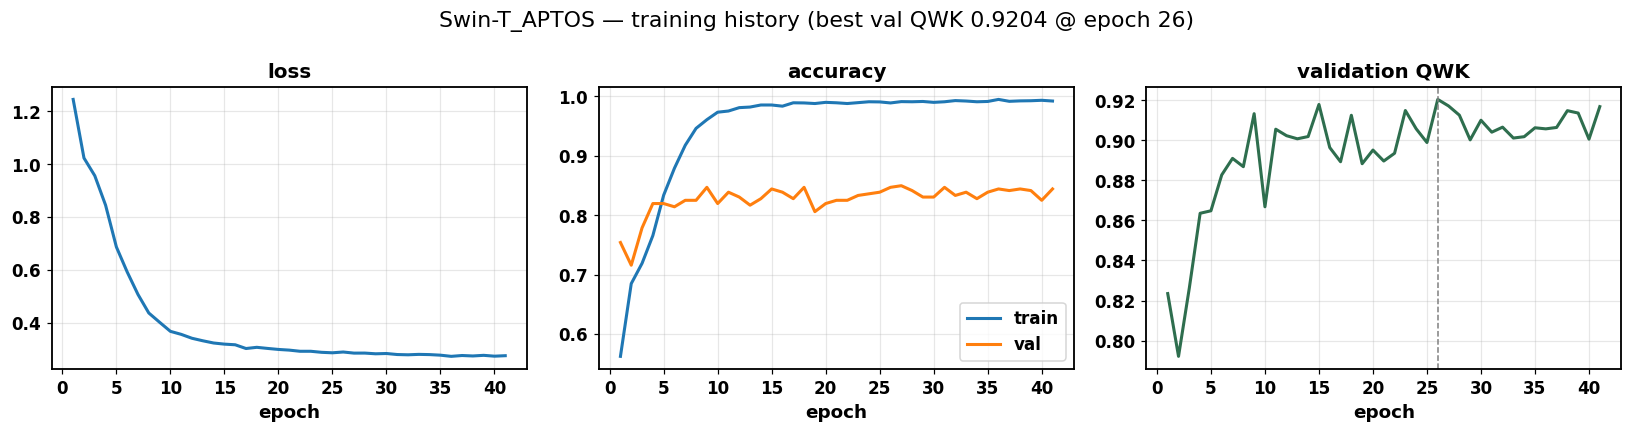

In [12]:
# ---------------------------------------------------------------
# TRAINING CURVES
# ---------------------------------------------------------------
import matplotlib.pyplot as plt

ep = range(1, len(history["train_acc"]) + 1)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(ep, history["train_loss"], label="train"); ax[0].set_title("loss")
ax[1].plot(ep, history["train_acc"], label="train")
ax[1].plot(ep, history["val_acc"], label="val"); ax[1].set_title("accuracy"); ax[1].legend()
ax[2].plot(ep, history["val_qwk"], color="#2E6E4E"); ax[2].set_title("validation QWK")
ax[2].axvline(best_epoch, ls="--", c="grey", lw=1)
for a in ax:
    a.set_xlabel("epoch"); a.grid(alpha=.3)
plt.suptitle(f"{RUN_TAG} — training history (best val QWK {best_qwk:.4f} @ epoch {best_epoch})")
plt.tight_layout()
plt.savefig(os.path.join(cfg.OUT_DIR, "curves.png"), dpi=140, bbox_inches="tight")
plt.show()

## 6 · Test-set grading performance

The model must be clinically competent before any XAI claim is meaningful. Per-class metrics
are reported with **explicit support counts** — Class 1 has only 5 test images, so its
precision/recall are high-variance and must not be over-interpreted.

In [13]:
# ---------------------------------------------------------------
# LOAD BEST CHECKPOINT AND EVALUATE ON THE OFFICIAL TEST SET
# ---------------------------------------------------------------
model.load_state_dict(torch.load(os.path.join(cfg.OUT_DIR, cfg.CKPT),
                                 map_location=device))
model.eval()

test_acc, test_qwk, y_true, y_pred = evaluate(test_ld)
print("=" * 62)
print(f"TEST SET — {RUN_TAG}   (stratified 70/15/15 test split, n={len(y_true)})")
print("=" * 62)
print(f"  Accuracy : {test_acc:.4f}")
print(f"  QWK      : {test_qwk:.4f}")
print(f"  n        : {len(y_true)}")
print("=" * 62)

rep = classification_report(y_true, y_pred, output_dict=True, zero_division=0,
                            labels=list(range(cfg.NUM_CLASSES)))
rows = []
for k in range(cfg.NUM_CLASSES):
    r = rep[str(k)]
    rows.append({"class": f"Class {k}", "precision": round(r["precision"], 4),
                 "recall": round(r["recall"], 4), "f1": round(r["f1-score"], 4),
                 "support": int(r["support"])})
perclass = pd.DataFrame(rows)
print("\nPer-class metrics:")
print(perclass.to_string(index=False))

small = perclass[perclass["support"] < 10]
if len(small):
    print("\n** HIGH-VARIANCE CLASSES (support < 10) — flag in limitations: **")
    print(small[["class", "support"]].to_string(index=False))

json.dump({"test_acc": test_acc, "test_qwk": test_qwk,
           "best_val_qwk": best_qwk, "n_test": int(len(y_true)),
           "per_class": rows},
          open(os.path.join(cfg.OUT_DIR, "test_metrics.json"), "w"), indent=2)
perclass.to_csv(os.path.join(cfg.OUT_DIR, "per_class_metrics.csv"), index=False)

TEST SET — Swin-T_APTOS   (stratified 70/15/15 test split, n=366)
  Accuracy : 0.8415
  QWK      : 0.8858
  n        : 366

Per-class metrics:
  class  precision  recall     f1  support
Class 0     0.9849  0.9849 0.9849      199
Class 1     0.5806  0.6000 0.5902       30
Class 2     0.7030  0.8161 0.7553       87
Class 3     0.4706  0.4706 0.4706       17
Class 4     0.8333  0.4545 0.5882       33


In [14]:
print("MODEL_NAME:", cfg.MODEL_NAME)
print("IS_VIT    :", IS_VIT)
print("RUN_TAG   :", RUN_TAG)

MODEL_NAME: swin_tiny_patch4_window7_224
IS_VIT    : False
RUN_TAG   : Swin-T_APTOS


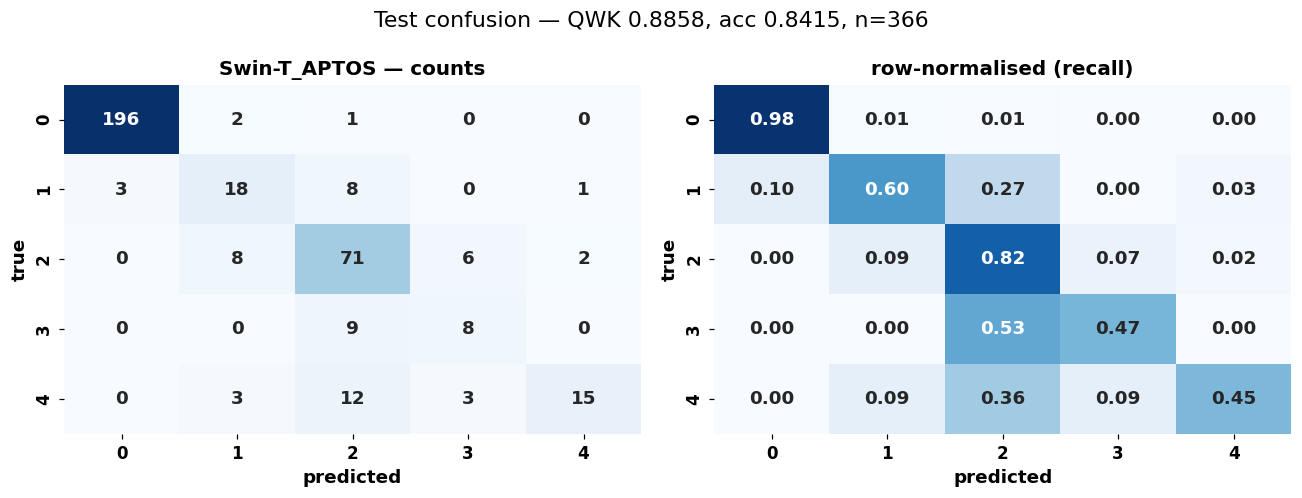

In [15]:
# ---------------------------------------------------------------
# CONFUSION MATRIX
# ---------------------------------------------------------------
import seaborn as sns

cm = confusion_matrix(y_true, y_pred, labels=list(range(cfg.NUM_CLASSES)))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0])
ax[0].set_title(f"{RUN_TAG} — counts"); ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true")
cmn = cm.astype(float) / np.maximum(cm.sum(1, keepdims=True), 1)
sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=ax[1], vmin=0, vmax=1)
ax[1].set_title("row-normalised (recall)"); ax[1].set_xlabel("predicted"); ax[1].set_ylabel("true")
plt.suptitle(f"Test confusion — QWK {test_qwk:.4f}, acc {test_acc:.4f}, n={len(y_true)}")
plt.tight_layout()
plt.savefig(os.path.join(cfg.OUT_DIR, "confusion.png"), dpi=140, bbox_inches="tight")
plt.show()

## 7 · The explainers

Five attribution methods behind a single interface:

```python
explainer(model, img_norm, target) -> HxW map in [0, 1]
```

**Naming honesty**: Attention-Rollout is ill-defined under Swin's shifted-window attention,
so the Swin runs register a clearly-labelled **TokenNorm surrogate** instead. The two are
never conflated in tables or figures.

In [16]:
# ---------------------------------------------------------------
# Shared utilities
# ---------------------------------------------------------------
from skimage.filters import gaussian as sk_gaussian

def to_2d_uint(attr_hw: np.ndarray) -> np.ndarray:
    """Min-max normalize a 2-D map to [0,1]."""
    a = attr_hw.astype(np.float32)
    return (a - a.min()) / (a.max() - a.min() + 1e-8)

def blurred_baseline(img_norm: torch.Tensor) -> torch.Tensor:
    """(1,3,H,W) normalized -> Gaussian-blurred version, still normalized."""
    img01 = denorm(img_norm).squeeze(0).permute(1, 2, 0).cpu().numpy()
    blur = sk_gaussian(img01, sigma=cfg.BLUR_SIGMA, channel_axis=2)
    t = torch.tensor(blur, dtype=torch.float32, device=device).permute(2, 0, 1).unsqueeze(0)
    return renorm(t)

def upsample_to_input(map_lowres: np.ndarray) -> np.ndarray:
    """Bilinearly upsample a low-res map to (IMG_SIZE, IMG_SIZE), renormalized to [0,1]."""
    t = torch.tensor(map_lowres, dtype=torch.float32)[None, None]
    t = F.interpolate(t, size=(cfg.IMG_SIZE, cfg.IMG_SIZE), mode="bilinear", align_corners=False)
    return to_2d_uint(t.squeeze().numpy())

In [17]:
# ---------------------------------------------------------------
# 6.1 Input-gradient saliency (BASELINE ONLY)
# NOTE: every explainer below takes `model` as its FIRST argument and hooks
# THAT model. This is essential for the randomization sanity check (Section 9),
# where each method must run on a *different* (randomized) model.
# ---------------------------------------------------------------
def explain_input_gradient(model: nn.Module, img_norm: torch.Tensor, target: int) -> np.ndarray:
    """Raw |d score / d input|, channel-averaged. Weak baseline, kept honest."""
    model.eval()
    x = img_norm.clone().to(device).requires_grad_(True)
    score = model(x)[0, target]
    model.zero_grad(set_to_none=True)
    score.backward()
    g = x.grad.detach().abs().mean(1).squeeze().cpu().numpy()
    return to_2d_uint(g)

In [18]:
# ---------------------------------------------------------------
# 6.2 Grad-CAM — architecture-aware (Swin hierarchical OR ViT patch tokens).
#     Uses cam_target_layer() + tokens_to_patch_grid() so one body serves both.
#     A runtime assert guarantees activation/gradient spatial shapes match.
# ---------------------------------------------------------------
def explain_gradcam(model: nn.Module, img_norm: torch.Tensor, target: int) -> np.ndarray:
    model.eval()
    store: Dict[str, torch.Tensor] = {}
    layer = cam_target_layer(model)
    fh = layer.register_forward_hook(lambda m, i, o: store.__setitem__("a", o))
    bh = layer.register_full_backward_hook(lambda m, gi, go: store.__setitem__("g", go[0]))
    try:
        x = img_norm.clone().to(device).requires_grad_(True)
        out = model(x); model.zero_grad(set_to_none=True)
        out[0, target].backward()
        acts  = tokens_to_patch_grid(store["a"].detach())   # (C,h,w)
        grads = tokens_to_patch_grid(store["g"].detach())   # (C,h,w)
        assert acts.shape == grads.shape, (
            f"Grad-CAM activation/gradient shape mismatch: "
            f"acts {tuple(acts.shape)} vs grads {tuple(grads.shape)}")
        weights = grads.mean(dim=(1, 2))                     # (C,)
        cam = torch.relu((weights[:, None, None] * acts).sum(0))
    finally:
        fh.remove(); bh.remove()
    return upsample_to_input(cam.cpu().numpy())

In [19]:
# ---------------------------------------------------------------
# 6.3 Attention map — architecture-aware.
#   ViT  : TRUE attention rollout. timm's fused-QKV Attention does not store
#          the post-softmax matrix, so we recompute it per block from qkv,
#          average heads, add residual identity, normalize, and compose across
#          all blocks (Abnar & Zuidema, 2020). The CLS row gives patch scores.
#   Swin : windowed attention is not exposed cleanly across timm versions, so
#          we use a token-norm SURROGATE (final-stage embedding L2 norm), which
#          still depends on the learned weights. Registered as a surrogate.
# ---------------------------------------------------------------
def _vit_attention_rollout(model: nn.Module, img_norm: torch.Tensor) -> np.ndarray:
    attns: List[torch.Tensor] = []
    handles = []
    def make_hook(attn_module):
        def hook(module, inp, out):
            tokens = inp[0]                      # (B,N,C) entering attention
            B, N, C = tokens.shape
            h = module.num_heads; d = C // h
            qkv = module.qkv(tokens).reshape(B, N, 3, h, d).permute(2, 0, 3, 1, 4)
            q, k = qkv[0], qkv[1]
            a = (q @ k.transpose(-2, -1)) * (d ** -0.5)
            a = a.softmax(dim=-1)                # (B,h,N,N)
            attns.append(a.mean(1).detach())     # head-avg -> (B,N,N)
        return hook
    for blk in model.blocks:
        handles.append(blk.attn.register_forward_hook(make_hook(blk.attn)))
    try:
        with torch.no_grad():
            _ = model(img_norm.to(device))
    finally:
        for hd in handles:
            hd.remove()
    res = torch.eye(attns[0].size(-1), device=attns[0].device)
    for A in attns:
        A = A[0]; A = A + torch.eye(A.size(-1), device=A.device)
        A = A / A.sum(-1, keepdim=True)
        res = A @ res
    cls = res[0, 1:]                              # CLS -> patches
    s = int(round(math.sqrt(cls.numel())))
    return cls.reshape(s, s).cpu().numpy()

def explain_attention(model: nn.Module, img_norm: torch.Tensor, target: int) -> np.ndarray:
    model.eval()
    if IS_VIT:
        return upsample_to_input(_vit_attention_rollout(model, img_norm))
    # Swin surrogate: final-stage token L2 norm
    store: Dict[str, torch.Tensor] = {}
    layer = cam_target_layer(model)
    h = layer.register_forward_hook(lambda m, i, o: store.__setitem__("z", o.detach()))
    try:
        with torch.no_grad():
            _ = model(img_norm.to(device))
    finally:
        h.remove()
    z = store["z"]
    if z.dim() == 4:                              # (B,H,W,C)
        s = z.shape[1]; tok = z.norm(dim=-1).reshape(s, s)
    else:                                         # (B,N,C), N a perfect square
        N = z.shape[1]; s = int(round(math.sqrt(N)))
        assert s * s == N, f"Swin token count {N} is not a perfect square"
        tok = z.norm(dim=-1).reshape(s, s)
    return upsample_to_input(tok.cpu().numpy())

In [20]:
# ---------------------------------------------------------------
# 6.4 Integrated Gradients (Captum) with blurred baseline.
#     IG is built on the PASSED model INSIDE the call (rebuilding per call is
#     correct and cheap) so the randomization sanity check sees the randomized
#     model rather than a stale global. n_steps is now cfg.IG_STEPS.
# ---------------------------------------------------------------
from captum.attr import IntegratedGradients

def explain_integrated_gradients(model: nn.Module, img_norm: torch.Tensor, target: int) -> np.ndarray:
    model.eval()
    x = img_norm.clone().to(device)
    base = blurred_baseline(x)
    ig = IntegratedGradients(model)              # bound to THIS model
    attr = ig.attribute(x, baselines=base, target=int(target), n_steps=cfg.IG_STEPS)
    a = attr.detach().abs().mean(1).squeeze().cpu().numpy()
    return to_2d_uint(a)

In [21]:
# ---------------------------------------------------------------
# 6.5 Transformer-Attribution (Chefer-style) — architecture-aware.
#     relu(sum(z * dz)) over the final-block token embeddings; CLS dropped for ViT.
#     A runtime assert guarantees the embedding/gradient shapes match.
# ---------------------------------------------------------------
def explain_transformer_attribution(model: nn.Module, img_norm: torch.Tensor, target: int) -> np.ndarray:
    model.eval()
    store: Dict[str, torch.Tensor] = {}
    layer = cam_target_layer(model)
    fh = layer.register_forward_hook(lambda m, i, o: store.__setitem__("z", o))
    bh = layer.register_full_backward_hook(lambda m, gi, go: store.__setitem__("g", go[0]))
    try:
        x = img_norm.clone().to(device).requires_grad_(True)
        out = model(x); model.zero_grad(set_to_none=True)
        out[0, target].backward()
        z = store["z"].detach()[0]               # (N,C)
        g = store["g"].detach()[0]
        assert z.shape == g.shape, (
            f"TransformerAttribution embedding/gradient shape mismatch: "
            f"z {tuple(z.shape)} vs g {tuple(g.shape)}")
        rel = torch.relu((z * g).sum(-1))        # (N,)
        grid = tokens_vec_to_grid(rel)           # drops CLS for ViT
    finally:
        fh.remove(); bh.remove()
    return upsample_to_input(grid.cpu().numpy())

In [22]:
# ---------------------------------------------------------------
# EXPLAINER REGISTRY: name -> fn(model, img_norm, target) -> HxW map in [0,1].
# The Swin attention entry is labelled a SURROGATE so it is never conflated
# with ViT's true rollout in any table or figure.
# ---------------------------------------------------------------
_ATTENTION_NAME = "AttentionRollout" if IS_VIT else "TokenNorm (Swin surrogate)"

EXPLAINERS: Dict[str, Callable[[nn.Module, torch.Tensor, int], np.ndarray]] = {
    "InputGrad (baseline)":     explain_input_gradient,
    "GradCAM":                  explain_gradcam,
    _ATTENTION_NAME:            explain_attention,
    "IntegratedGradients":      explain_integrated_gradients,
    "TransformerAttribution":   explain_transformer_attribution,
}
log.info("attention explainer registered as: %s", _ATTENTION_NAME)

# SELF-TEST: every explainer must return a finite HxW map on a real image.
_xi, _yi = test_ds[0]
for _name, _fn in EXPLAINERS.items():
    _m = _fn(model, _xi.unsqueeze(0), _yi)
    assert _m.shape == (cfg.IMG_SIZE, cfg.IMG_SIZE), (_name, _m.shape)
    assert np.isfinite(_m).all(), f"{_name} produced non-finite values"
    assert _m.min() >= -1e-6 and _m.max() <= 1 + 1e-6, f"{_name} not in [0,1]"
print("All explainers OK:")
for _n in EXPLAINERS: print("   -", _n)

All explainers OK:
   - InputGrad (baseline)
   - GradCAM
   - TokenNorm (Swin surrogate)
   - IntegratedGradients
   - TransformerAttribution


## 8 · Axis 1 — Faithfulness (deletion / insertion)

**Deletion** progressively replaces the most-attributed pixels with a blurred baseline; a
faithful map makes the target probability fall fast (**lower AUC is better**).
**Insertion** does the reverse from the baseline (**higher AUC is better**).

Both are reported over a balanced held-out subset, for each of three seeds. Where a class
has fewer test images than the requested per-class quota, the **effective n is reported
truthfully** rather than padded — and if every seed draws the identical subset, the
resulting zero standard deviation is flagged as an artifact, not robustness.

In [23]:
def _auc(curve) -> float:
    c = np.asarray(curve, dtype=np.float64)
    _trap = getattr(np, "trapezoid", None) or np.trapz
    return float(_trap(c, dx=1.0 / (len(c) - 1)))

def blurred_baseline(img: torch.Tensor) -> torch.Tensor:
    """Blurred image as the perturbation baseline (preserves colour statistics,
    unlike a zero/black baseline which is far outside the data manifold)."""
    import torchvision.transforms.functional as TF
    return TF.gaussian_blur(img, kernel_size=51, sigma=[15.0, 15.0])

In [24]:
@torch.no_grad()
def deletion_insertion(model: nn.Module, img_norm: torch.Tensor, attr_hw: np.ndarray,
                       target: int, steps: Optional[int] = None,
                       mode: str = "deletion") -> float:
    """AUC of the target-probability curve as pixels are removed/restored,
    most-important first. Probability is recorded AFTER each write and the
    curve reaches the fully-perturbed endpoint (no wasted/missing write)."""
    steps = steps or cfg.DELINS_STEPS
    model.eval()
    img  = img_norm.to(device).contiguous()
    base = blurred_baseline(img).contiguous()

    order = np.argsort(attr_hw.flatten())[::-1]
    n = order.size
    chunk = max(1, n // steps)

    cur = (img if mode == "deletion" else base).clone().contiguous()
    srcT = (base if mode == "deletion" else img).contiguous()
    cur_flat, src_flat = cur.view(1, 3, -1), srcT.view(1, 3, -1)

    probs = [torch.softmax(model(cur), 1)[0, target].item()]
    for i in range(math.ceil(n / chunk)):
        idx = order[i * chunk:(i + 1) * chunk]
        if len(idx) == 0:
            break
        idx_t = torch.tensor(idx.copy(), device=device, dtype=torch.long)
        cur_flat[:, :, idx_t] = src_flat[:, :, idx_t]
        probs.append(torch.softmax(model(cur), 1)[0, target].item())
    return _auc(probs)

In [25]:
# ---------------------------------------------------------------
# Balanced held-out XAI subset, sampled per seed.
# Classes with fewer than XAI_N_PER_CLASS test images use ALL of them and the
# shortfall is REPORTED — never silently padded.
# ---------------------------------------------------------------
from collections import defaultdict

by_class = defaultdict(list)
for idx, (_, y) in enumerate(test_ds.samples):
    by_class[y].append(idx)

def build_xai_subset(seed: int, verbose: bool = False) -> List[int]:
    rng = random.Random(seed)
    subset, per_class_n = [], {}
    for c in range(cfg.NUM_CLASSES):
        pool = list(by_class[c]); rng.shuffle(pool)
        take = pool[:cfg.XAI_N_PER_CLASS]
        per_class_n[c] = len(take)
        subset += take
    if verbose:
        log.info("[seed %d] per-class n: %s (total %d)", seed, per_class_n, len(subset))
    return subset

_rows = []
for s in cfg.SEEDS_FOR_VARIANCE:
    idxs = build_xai_subset(s)
    cnt = pd.Series([test_ds.samples[i][1] for i in idxs]).value_counts().sort_index()
    _rows.append({"seed": s, **{f"class{k}": int(cnt.get(k, 0)) for k in range(5)},
                  "total": len(idxs)})
subset_tab = pd.DataFrame(_rows)
print("Effective XAI subset per seed:")
print(subset_tab.to_string(index=False))

# Do the seeds actually draw DIFFERENT subsets? If not, std=0 is an artifact.
_sets = [set(build_xai_subset(s)) for s in cfg.SEEDS_FOR_VARIANCE]
MULTISEED_VARIANCE_REAL = not all(a == _sets[0] for a in _sets)
print(f"\nmultiseed_variance_real = {MULTISEED_VARIANCE_REAL}")
if not MULTISEED_VARIANCE_REAL:
    print("** Every seed drew the SAME subset (classes exhausted).")
    print("   Report as SINGLE-SEED; std=0 here is an artifact, not robustness. **")

Effective XAI subset per seed:
 seed  class0  class1  class2  class3  class4  total
   42      12      12      12      12      12     60
    1      12      12      12      12      12     60
    7      12      12      12      12      12     60

multiseed_variance_real = True


In [26]:
# ---------------------------------------------------------------
# FAITHFULNESS SWEEP  (the slow cell)
# Targets the PREDICTED grade; stores true/pred/correct for stratification.
# ---------------------------------------------------------------
def run_faithfulness_for_seed(seed: int) -> pd.DataFrame:
    set_seed(seed)
    idxs = build_xai_subset(seed)
    recs = []
    for j, i in enumerate(tqdm(idxs, desc=f"faithfulness seed {seed}", leave=False)):
        x, y_true_i = test_ds[i]
        x = x.unsqueeze(0)
        with torch.no_grad():
            pred = int(model(x.to(device)).argmax(1).item())
        for name, fn in EXPLAINERS.items():
            attr = fn(model, x, pred)
            recs.append({
                "seed": seed, "idx": i, "image_idx": i,   # alias: inherited cells use image_idx
                "explainer": name, "method": name,       # alias: inherited cells use method
                "true": int(y_true_i), "pred": pred,
                "correct": int(pred == y_true_i),
                "deletion": deletion_insertion(model, x, attr, pred, mode="deletion"),
                "insertion": deletion_insertion(model, x, attr, pred, mode="insertion"),
            })
    return pd.DataFrame(recs)

faith_raw = pd.concat([run_faithfulness_for_seed(s) for s in cfg.SEEDS_FOR_VARIANCE],
                      ignore_index=True)
faith_raw.to_csv(os.path.join(cfg.OUT_DIR, "faithfulness_raw.csv"), index=False)
log.info("faithfulness records: %d", len(faith_raw))

# per-seed means, then mean +/- std ACROSS seeds
per_seed = faith_raw.groupby(["explainer", "seed"])[["deletion", "insertion"]].mean()
agg = per_seed.groupby("explainer").agg(["mean", "std"])
faith_tab = pd.DataFrame({
    "deletion_mean":  agg[("deletion", "mean")].round(4),
    "deletion_std":   agg[("deletion", "std")].round(4),
    "insertion_mean": agg[("insertion", "mean")].round(4),
    "insertion_std":  agg[("insertion", "std")].round(4),
}).sort_values("insertion_mean", ascending=False)

print("=" * 78)
print("FAITHFULNESS — deletion (lower better) / insertion (higher better)")
print("=" * 78)
print(faith_tab.to_string())
if not MULTISEED_VARIANCE_REAL:
    print("\n** std values are 0 by construction (identical subset each seed).")
    print("   Report these as SINGLE-SEED. **")
faith_tab.to_csv(os.path.join(cfg.OUT_DIR, "faithfulness_by_method.csv"))

faithfulness seed 42:   0%|          | 0/60 [00:00<?, ?it/s]

faithfulness seed 1:   0%|          | 0/60 [00:00<?, ?it/s]

faithfulness seed 7:   0%|          | 0/60 [00:00<?, ?it/s]

FAITHFULNESS — deletion (lower better) / insertion (higher better)
                            deletion_mean  deletion_std  insertion_mean  insertion_std
explainer                                                                             
IntegratedGradients                0.3199        0.0103          0.6128         0.0156
GradCAM                            0.4185        0.0096          0.6095         0.0139
TokenNorm (Swin surrogate)         0.4704        0.0113          0.5549         0.0176
TransformerAttribution             0.4866        0.0149          0.4676         0.0107
InputGrad (baseline)               0.4610        0.0177          0.3875         0.0153


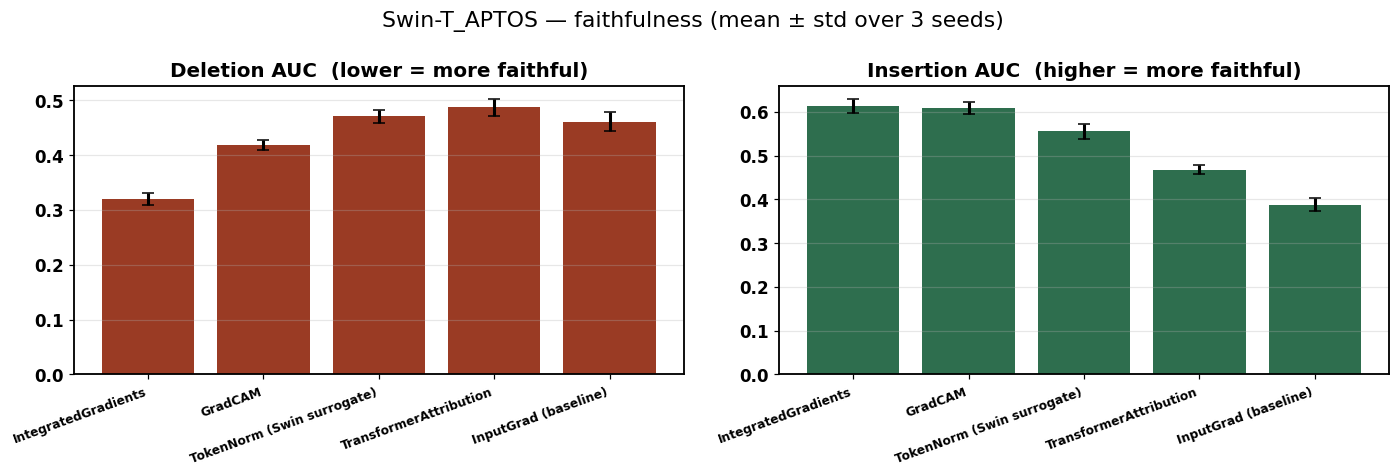


Faithfulness split by prediction correctness (correct=94/131 unique images):
                           deletion         insertion        
correct                           0       1         0       1
explainer                                                    
GradCAM                      0.3000  0.4855    0.5353  0.6515
InputGrad (baseline)         0.3844  0.5043    0.3097  0.4315
IntegratedGradients          0.2429  0.3634    0.5051  0.6737
TokenNorm (Swin surrogate)   0.3535  0.5364    0.4852  0.5943
TransformerAttribution       0.3638  0.5560    0.3378  0.5410


In [27]:
# ---------------------------------------------------------------
# FAITHFULNESS FIGURE + correctness split
# ---------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
meths = faith_tab.index.tolist()
xp = np.arange(len(meths))
yerr_d = faith_tab["deletion_std"].values if MULTISEED_VARIANCE_REAL else None
yerr_i = faith_tab["insertion_std"].values if MULTISEED_VARIANCE_REAL else None

ax[0].bar(xp, faith_tab["deletion_mean"], yerr=yerr_d, capsize=4, color="#9A3B24")
ax[0].set_title("Deletion AUC  (lower = more faithful)")
ax[1].bar(xp, faith_tab["insertion_mean"], yerr=yerr_i, capsize=4, color="#2E6E4E")
ax[1].set_title("Insertion AUC  (higher = more faithful)")
for a in ax:
    a.set_xticks(xp); a.set_xticklabels(meths, rotation=20, ha="right", fontsize=8)
    a.grid(axis="y", alpha=.3)
note = "mean ± std over 3 seeds" if MULTISEED_VARIANCE_REAL else "single-seed (no error bars)"
plt.suptitle(f"{RUN_TAG} — faithfulness ({note})")
plt.tight_layout()
plt.savefig(os.path.join(cfg.OUT_DIR, "faithfulness_by_method.png"), dpi=140,
            bbox_inches="tight")
plt.show()

n_corr = int(faith_raw.drop_duplicates("idx")["correct"].sum())
n_tot  = int(faith_raw["idx"].nunique())
print(f"\nFaithfulness split by prediction correctness "
      f"(correct={n_corr}/{n_tot} unique images):")
split_tab = (faith_raw.groupby(["explainer", "correct"])[["deletion", "insertion"]]
             .mean().round(4).unstack())
print(split_tab.to_string())

## 9 · Axis 2 — Sanity (cascading model randomization)

Adebayo et al. (2018): progressively re-initialise the layers closest to the output and
measure how much the attribution changes. An explainer that stays highly correlated with
its original map as the model is destroyed is **not actually reading the model** — it fails
the sanity check regardless of how faithful it looked.

**Kaiming re-initialisation, not zeros** — zeroing collapses LayerNorm and produces a
degenerate forward pass, which would silently invalidate the test.

Sanity frac=0.25:   0%|          | 0/30 [00:00<?, ?it/s]

Sanity frac=0.5:   0%|          | 0/30 [00:00<?, ?it/s]

Sanity frac=1.0:   0%|          | 0/30 [00:00<?, ?it/s]

SANITY CHECK — mean |Spearman| trained-vs-randomized, n=30 images
LOWER = better (map depends on learned weights).
valid_frac<1 at fraction=1.0 => maps went degenerate on a random model (EXPECTED, good).
Mean |Spearman| (lower = better):


fraction_randomized,0.25,0.50,1.00
method,,,
GradCAM,0.179,0.172,0.201
InputGrad (baseline),0.463,0.375,0.117
IntegratedGradients,0.752,0.731,0.575
TokenNorm (Swin surrogate),0.204,0.190,0.228
TransformerAttribution,0.161,0.157,0.187


Valid fraction (share of defined maps):


fraction_randomized,0.25,0.50,1.00
method,,,
GradCAM,0.97,0.77,0.83
InputGrad (baseline),1.00,1.00,1.00
IntegratedGradients,1.00,1.00,1.00
TokenNorm (Swin surrogate),1.00,1.00,1.00
TransformerAttribution,1.00,0.73,0.83


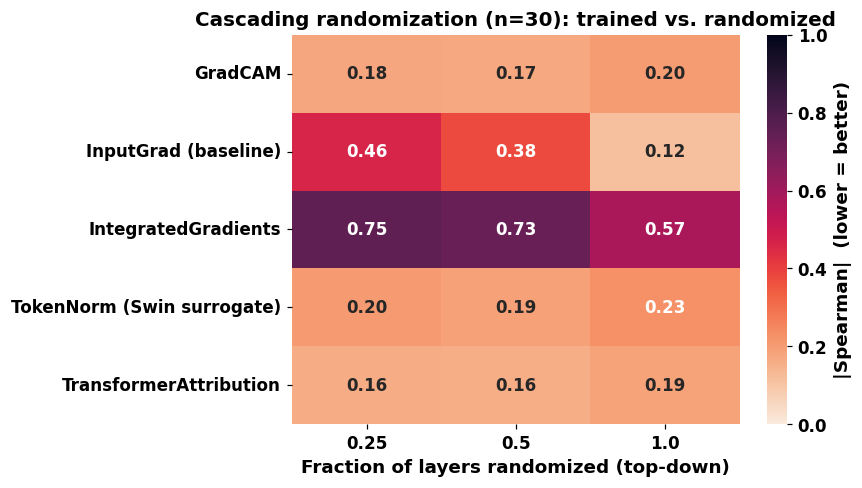

In [28]:
# =====================================================================
# 9 · Cascading model-randomization test (Adebayo et al. 2018)
# =====================================================================
from scipy.stats import spearmanr
import copy

@torch.no_grad()
def randomize_top_fraction(trained_model: nn.Module, fraction: float,
                           seed: int = 123) -> nn.Module:
    """Deep-copy with the top `fraction` of Linear/Conv layers (closest to the
    output) re-initialized (Kaiming). LayerNorm/bias-only params are left intact
    so the forward pass stays finite. `.modules()` registration order tracks
    depth for timm ViT/Swin, so `layers[-k:]` are the output-proximal layers."""
    m = copy.deepcopy(trained_model).to(device).eval()
    layers = [mod for mod in m.modules() if isinstance(mod, (nn.Linear, nn.Conv2d))]
    k = max(1, int(round(len(layers) * fraction)))
    torch.manual_seed(seed)
    for mod in layers[-k:]:                       # top-k = closest to output
        if mod.weight is not None:
            nn.init.kaiming_normal_(mod.weight, nonlinearity="relu")
        if getattr(mod, "bias", None) is not None:
            nn.init.normal_(mod.bias, std=0.02)
    return m

def _safe_spearman(a: np.ndarray, b: np.ndarray) -> float:
    a = np.asarray(a, np.float64); b = np.asarray(b, np.float64)
    if a.std() < 1e-9 or b.std() < 1e-9:          # constant map -> undefined
        return np.nan
    rho = spearmanr(a, b).correlation
    return np.nan if rho is None else float(rho)

# Audit on correctly-classified images so the explanation target is meaningful.
# Column-name robustness: the faithfulness table may use 'image_idx' or 'idx'
# depending on which cell version produced it.
_IDX_COL = "image_idx" if "image_idx" in faith_raw.columns else "idx"
_correct_idx = faith_raw[faith_raw.correct == 1][_IDX_COL].unique()
log.info("sanity audit keyed on faith_raw column '%s'", _IDX_COL)
audit_idx = list(_correct_idx[:cfg.SANITY_N_IMAGES])
log.info("Sanity-check audit set: n = %d correctly-classified images", len(audit_idx))
fractions = [0.25, 0.5, 1.0]

# Guard against a silent no-op: randomization must change the logits.
_probe = randomize_top_fraction(model, 1.0)
with torch.no_grad():
    _xi, _ = test_ds[int(audit_idx[0])]
    _d = (model(_xi.unsqueeze(0).to(device)) -
          _probe(_xi.unsqueeze(0).to(device))).abs().mean().item()
assert _d > 1e-4, "Randomization had no effect — check the re-init logic."
log.info("[check] randomized vs trained mean logit diff = %.4f (OK, > 0)", _d)

sanity_rows = []
for frac in fractions:
    rmodel = randomize_top_fraction(model, frac)
    for idx in tqdm(audit_idx, desc=f"Sanity frac={frac}", leave=False):
        img, label = test_ds[int(idx)]
        img_norm = img.unsqueeze(0)
        with torch.no_grad():
            tgt = int(model(img_norm.to(device)).argmax(1).item())
        for name, fn in EXPLAINERS.items():
            a_true = fn(model,  img_norm, tgt).flatten()
            a_rand = fn(rmodel, img_norm, tgt).flatten()
            sanity_rows.append({"fraction_randomized": frac, "method": name,
                                "spearman": _safe_spearman(a_true, a_rand)})

sanity_df = pd.DataFrame(sanity_rows)
sanity_df["explainer"] = sanity_df["method"]   # alias for the scorecard

# Report the MAGNITUDE of the correlation (sign is not meaningful here).
sanity_df["abs_spearman"] = sanity_df["spearman"].abs()
summary = (sanity_df
           .groupby(["method", "fraction_randomized"])["abs_spearman"]
           .agg(abs_spearman_mean=lambda s: float(np.nanmean(s)) if np.any(~np.isnan(s)) else np.nan,
                valid_frac=lambda s: float(np.mean(~np.isnan(s))))
           .reset_index())

pivot_rho = summary.pivot(index="method", columns="fraction_randomized", values="abs_spearman_mean").round(3)
pivot_val = summary.pivot(index="method", columns="fraction_randomized", values="valid_frac").round(2)

print("="*70)
print(f"SANITY CHECK — mean |Spearman| trained-vs-randomized, n={len(audit_idx)} images")
print("LOWER = better (map depends on learned weights).")
print("valid_frac<1 at fraction=1.0 => maps went degenerate on a random model (EXPECTED, good).")
print("="*70)
try:
    from IPython.display import display
    print("Mean |Spearman| (lower = better):"); display(pivot_rho)
    print("Valid fraction (share of defined maps):"); display(pivot_val)
except Exception:
    print("Mean |Spearman|:"); print(pivot_rho.to_string())
    print("\nValid fraction:"); print(pivot_val.to_string())

sanity_df.to_csv(os.path.join(cfg.OUT_DIR, "sanity_randomization_raw.csv"), index=False)
summary.to_csv(os.path.join(cfg.OUT_DIR, "sanity_randomization_summary.csv"), index=False)

try:
    fig, ax = plt.subplots(figsize=(8, 4.6))
    sns.heatmap(pivot_rho, annot=True, fmt=".2f", cmap="rocket_r",
                vmin=0, vmax=1, ax=ax,
                annot_kws={"size": PUB["annot_fs"], "weight": "bold"},
                cbar_kws={"label": "|Spearman|  (lower = better)"})
    ax.set_title(f"Cascading randomization (n={len(audit_idx)}): trained vs. randomized")
    ax.set_xlabel("Fraction of layers randomized (top-down)"); ax.set_ylabel("")
    plt.tight_layout()
    save_fig(fig, "sanity_randomization.png")
    plt.show()
except Exception as e:
    log.warning("[plot skipped] %r", e)


In [29]:
# ---------------------------------------------------------------
# (Sanity verdict is computed in the scorecard cell, section 12,
#  directly from pivot_rho produced above. This cell is retained as a
#  no-op so downstream cell numbering is unchanged.)
# ---------------------------------------------------------------
SANITY_THRESHOLD = 0.30
log.info('sanity threshold set: |rho| < %.2f', SANITY_THRESHOLD)

## 10 · Axis 3 — Plausibility: **not applicable to APTOS-2019**

Plausibility asks whether an attribution lands on *actual pathology*, which requires
pixel-level lesion annotation. APTOS-2019 provides image-level severity labels only and
ships no lesion masks, so this axis cannot be computed here — a property of the dataset,
not a gap in this pipeline.

Plausibility is reported for **IDRiD only** (n=81 segmentation images with MA/HE/EX/SE
masks). When tabulating results across all four configurations, leave the APTOS
plausibility cells explicitly marked *N/A* rather than blank, so a reader does not read
an empty cell as a missing experiment.

In [30]:
# ---------------------------------------------------------------
# PLAUSIBILITY — N/A for APTOS. Recorded explicitly so the run summary and
# any cross-dataset table can state the asymmetry rather than leave a hole.
# ---------------------------------------------------------------
PLAUSIBILITY_COMPUTED = False
plaus_union = None
plaus_lesion = None

print("=" * 78)
print("PLAUSIBILITY — N/A for APTOS-2019")
print("=" * 78)
print("APTOS-2019 contains no pixel-level lesion annotation, so explainer")
print("attributions cannot be scored against ground-truth pathology.")
print()
print("This benchmark therefore reports TWO axes for APTOS:")
print("   1. Faithfulness  (deletion / insertion)      -> computed")
print("   2. Sanity        (model randomization)       -> computed")
print("   3. Plausibility  (lesion-mask agreement)     -> N/A, no masks exist")
print()
print("For IDRiD, all three axes are computed (plausibility n=81).")
print("State this asymmetry explicitly in the manuscript.")
print("=" * 78)

PLAUSIBILITY — N/A for APTOS-2019
APTOS-2019 contains no pixel-level lesion annotation, so explainer
attributions cannot be scored against ground-truth pathology.

This benchmark therefore reports TWO axes for APTOS:
   1. Faithfulness  (deletion / insertion)      -> computed
   2. Sanity        (model randomization)       -> computed
   3. Plausibility  (lesion-mask agreement)     -> N/A, no masks exist

For IDRiD, all three axes are computed (plausibility n=81).
State this asymmetry explicitly in the manuscript.


## 11 · Qualitative panel

One row per DR grade, all explainers side by side. These are illustrative, not evidence —
the quantitative axes above carry the argument.

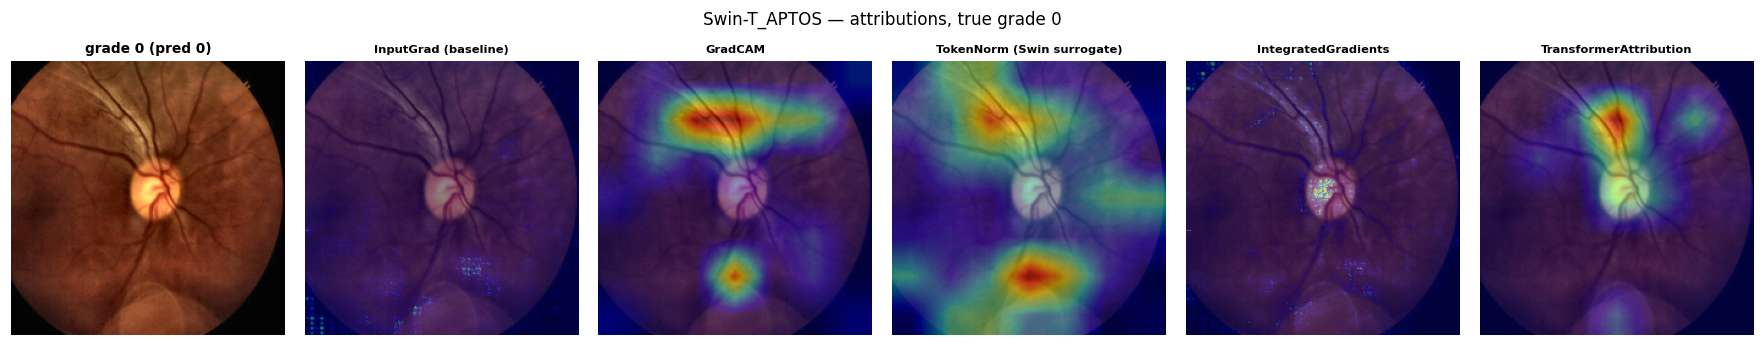

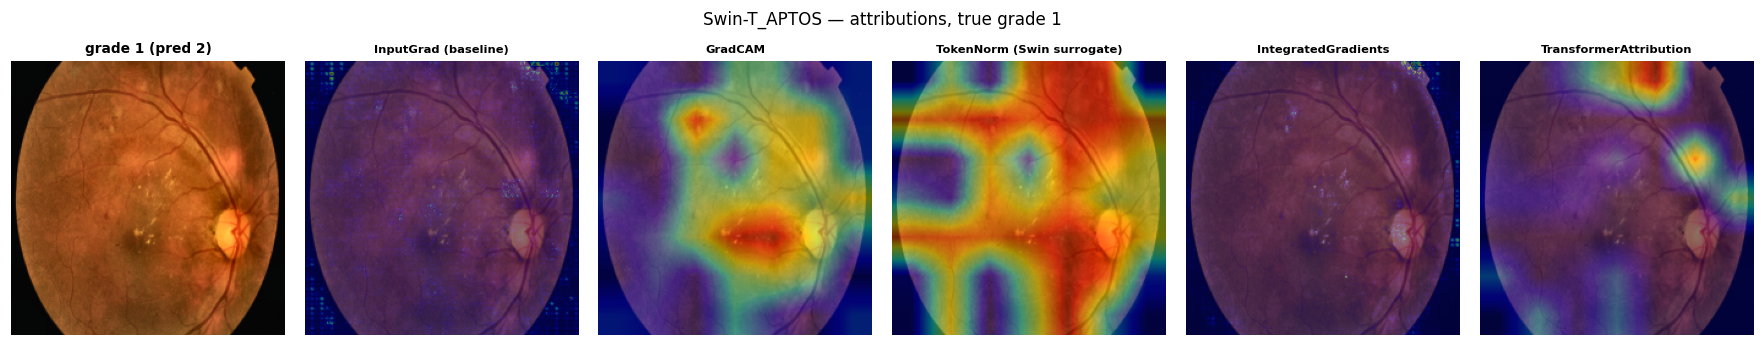

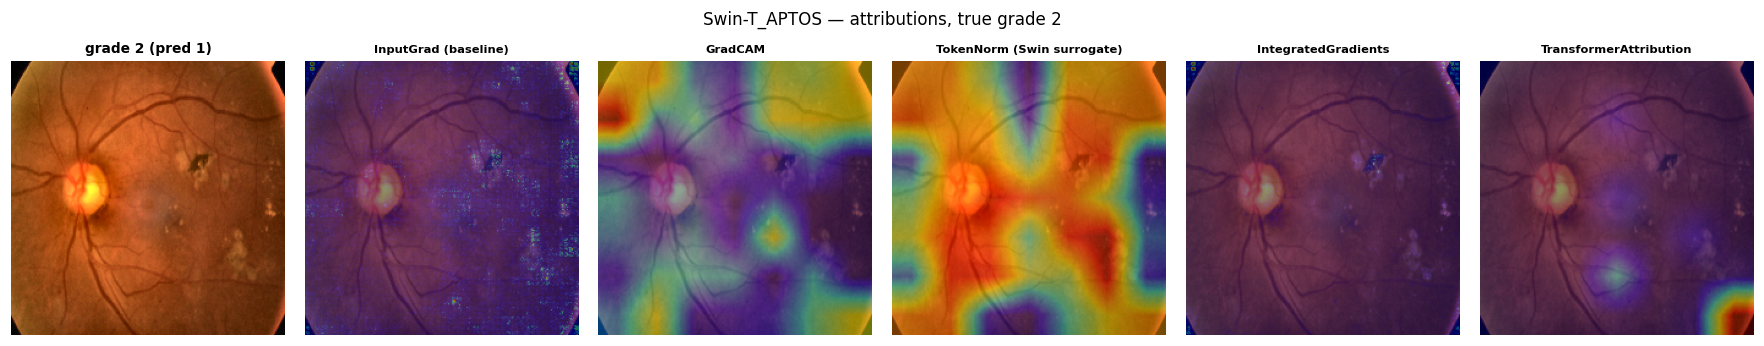

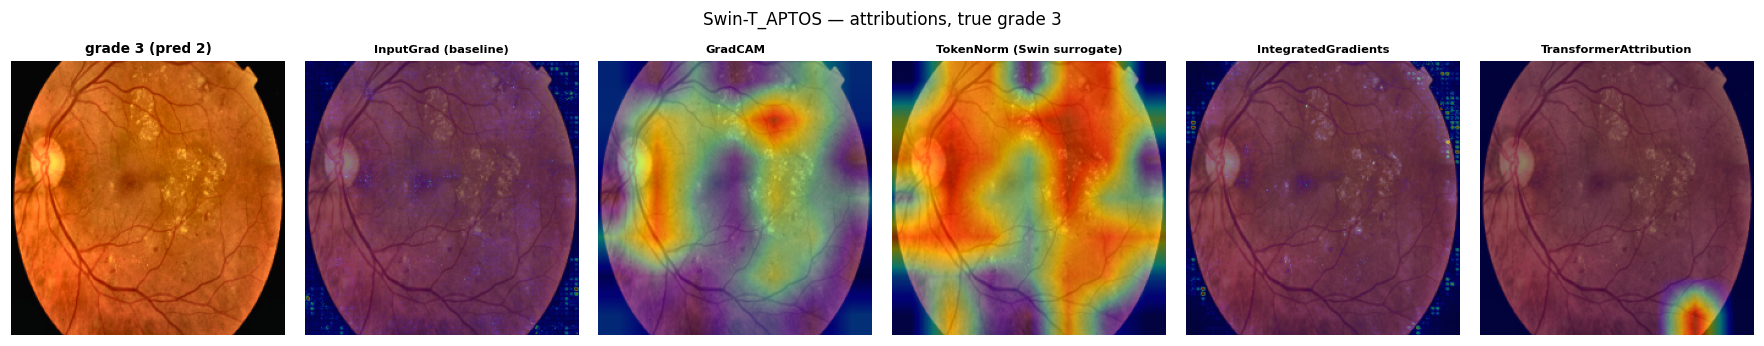

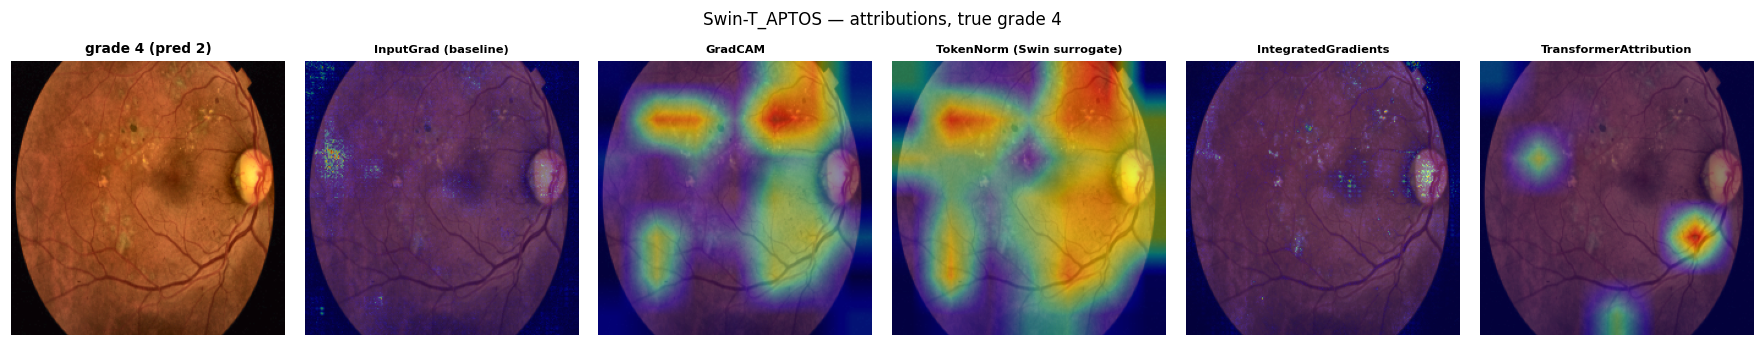

In [31]:
def show_panel_for_grade(grade: int) -> None:
    pool = by_class.get(grade, [])
    if not pool:
        log.warning("no test images for grade %d", grade); return
    i = pool[len(pool) // 2]
    x, y = test_ds[i]
    x = x.unsqueeze(0)
    with torch.no_grad():
        pred = int(model(x.to(device)).argmax(1).item())

    n = len(EXPLAINERS) + 1
    fig, axes = plt.subplots(1, n, figsize=(2.7 * n, 3.2))
    base = denorm(x.to(device))[0].permute(1, 2, 0).cpu().numpy()
    axes[0].imshow(base)
    axes[0].set_title(f"grade {grade} (pred {pred})", fontsize=9); axes[0].axis("off")
    for j, (name, fn) in enumerate(EXPLAINERS.items(), 1):
        m = fn(model, x, pred)
        axes[j].imshow(base); axes[j].imshow(m, cmap="jet", alpha=0.45)
        axes[j].set_title(name, fontsize=7.5); axes[j].axis("off")
    plt.suptitle(f"{RUN_TAG} — attributions, true grade {grade}", fontsize=11)
    plt.tight_layout()
    plt.savefig(os.path.join(cfg.OUT_DIR, f"panel_grade{grade}.png"),
                dpi=140, bbox_inches="tight")
    plt.show()

for g in range(cfg.NUM_CLASSES):
    show_panel_for_grade(g)

## 12 · Trustworthiness scorecard — two axes (plausibility N/A)

An explainer is trustworthy only if it is **faithful AND sanity-passing**. High
faithfulness alone is not enough: an attribution can track the model's computation
perfectly while being insensitive to the model's parameters — a sanity failure.

**Caveat for APTOS**: the third axis (plausibility) is unavailable here, so this verdict
rests on two axes only. A method can pass both and still highlight non-pathological
regions; only the IDRiD runs can test that. Compare the two verdicts before generalising.

In [32]:
# ---------------------------------------------------------------
# CONSOLIDATED SCORECARD — TWO AXES for APTOS (plausibility N/A)
# ---------------------------------------------------------------
score = pd.DataFrame(index=faith_tab.index)
score["faith_insertion"] = faith_tab["insertion_mean"]
score["faith_deletion"]  = faith_tab["deletion_mean"]
score["faith_rank"]      = faith_tab["insertion_mean"].rank(ascending=False).astype(int)

# Sanity: prefer the mean |rho| ACROSS fractions (more stable than a single
# cutoff at full randomization, which is sensitive to map degeneration).
SANITY_THRESHOLD = globals().get("SANITY_THRESHOLD", 0.30)

# --- WHY SOME |rho| CELLS ARE NaN -------------------------------------
# At full randomization an explainer's map can become CONSTANT (every pixel
# identical), which makes Spearman correlation undefined -> NaN, and drives
# valid_frac to 0. That is not a failed measurement: it means the map
# COLLAPSED once the learned weights were destroyed, which is exactly what a
# model-dependent explainer should do. Methods whose maps survive (valid_frac
# = 1.0) are the ones still producing structure from a random network.
#
# Consequence for reporting: a method with NaN at frac=1.0 has its mean |rho|
# averaged over FEWER fractions than one without. Always report valid_frac
# beside |rho| so the two are not read as equally-sampled numbers.
if "pivot_val" in dir():
    print("\nvalid_frac — share of images with a DEFINED correlation:")
    print(pivot_val.to_string())
    _degen = pivot_val[pivot_val.columns[-1]]
    _collapsed = list(_degen[_degen < 0.5].index)
    if _collapsed:
        print(f"\n  Maps collapsed at full randomization (valid_frac < 0.5): {_collapsed}")
        print("  -> Their |rho| at that fraction is NaN or rests on very few images.")
        print("     Report this alongside the verdict; it is EXPECTED behaviour,")
        print("     not a missing measurement.")
if "pivot_rho" in dir():
    _mean_rho = pivot_rho.mean(axis=1)                 # average over fractions
    _full_rho = pivot_rho[pivot_rho.columns[-1]]       # at full randomization
    score["sanity_mean_rho"] = _mean_rho.reindex(score.index).round(3)
    score["sanity_at_full"]  = _full_rho.reindex(score.index).round(3)
    score["sanity_pass"]     = np.where(
        score["sanity_mean_rho"] < SANITY_THRESHOLD, "YES", "NO")

    _alt = np.where(score["sanity_at_full"] < SANITY_THRESHOLD, "YES", "NO")
    _disagree = score.index[score["sanity_pass"].values != _alt]
    if len(_disagree):
        print("\n** THRESHOLD-SENSITIVE: verdict differs between the mean-across-"
              "fractions\n   criterion and the full-randomization-only criterion "
              f"for: {list(_disagree)}\n   Report BOTH; prefer the mean. **")
else:
    score["sanity_mean_rho"] = np.nan
    score["sanity_pass"]     = "n/a"

# Plausibility is N/A for APTOS (no lesion masks). The columns are kept so the
# table schema matches the IDRiD runs, but filled with NaN and labelled N/A.
score["plaus_auprc_ratio"] = np.nan
score["plaus_rank"] = np.nan

score = score.sort_values("faith_rank")
print("=" * 96)
print(f"TRUSTWORTHINESS SCORECARD — {RUN_TAG}")
print("=" * 96)
print(score.drop(columns=["plaus_auprc_ratio", "plaus_rank"]).to_string())
print("\n(plausibility columns omitted above: N/A for APTOS)")

# a method is TRUSTWORTHY only if it clears all available axes
# With only two axes available, "trustworthy" = faithful AND sanity-passing.
trust = score[score["sanity_pass"] == "YES"]
if len(trust):
    winner = trust.sort_values("faith_insertion", ascending=False).index[0]
    print(f"\nMOST TRUSTWORTHY: {winner}")
    print("  (highest faithfulness among methods that also pass sanity)")
    print("  NOTE: two-axis verdict — plausibility is N/A for APTOS, so this")
    print("  ranking cannot account for lesion agreement. Compare against the")
    print("  IDRiD three-axis verdict before drawing a general conclusion.")
else:
    winner = None
    print("\n** No method clears every axis — report this honestly. **")

score.to_csv(os.path.join(cfg.OUT_DIR, "trustworthiness_scorecard.csv"))


valid_frac — share of images with a DEFINED correlation:
fraction_randomized         0.25  0.50  1.00
method                                      
GradCAM                     0.97  0.77  0.83
InputGrad (baseline)        1.00  1.00  1.00
IntegratedGradients         1.00  1.00  1.00
TokenNorm (Swin surrogate)  1.00  1.00  1.00
TransformerAttribution      1.00  0.73  0.83

** THRESHOLD-SENSITIVE: verdict differs between the mean-across-fractions
   criterion and the full-randomization-only criterion for: ['InputGrad (baseline)']
   Report BOTH; prefer the mean. **
TRUSTWORTHINESS SCORECARD — Swin-T_APTOS
                            faith_insertion  faith_deletion  faith_rank  sanity_mean_rho  sanity_at_full sanity_pass
explainer                                                                                                           
IntegratedGradients                  0.6128          0.3199           1            0.686           0.575          NO
GradCAM                              0.

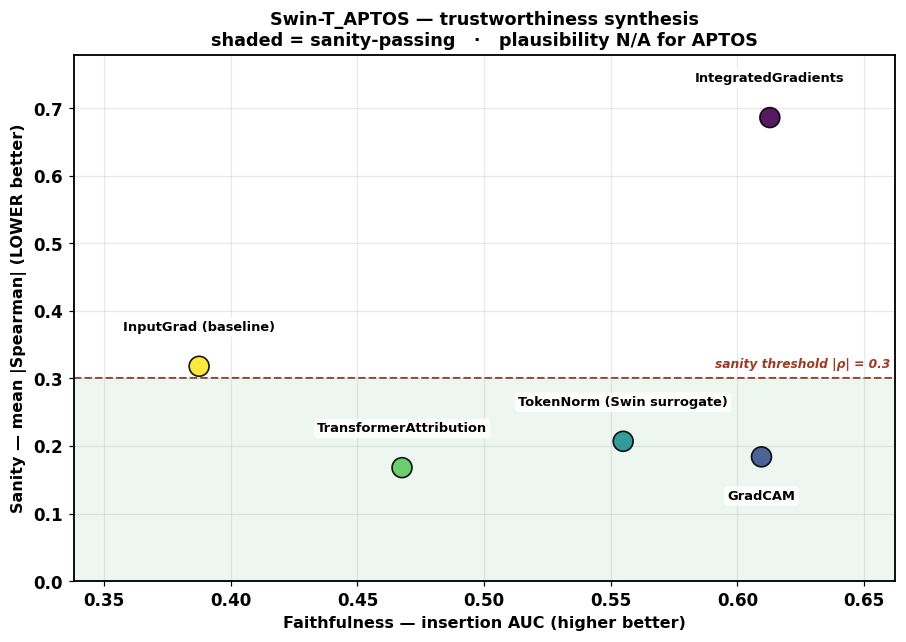

Trustworthy quadrant = high faithfulness (right) AND low |rho| (shaded).
Marker size is uniform: APTOS has no plausibility axis.


In [33]:
# ---------------------------------------------------------------
# TRUSTWORTHINESS SCATTER — the synthesis figure / graphical abstract
#
# Layout notes: methods can cluster tightly (TransformerAttribution and the
# Swin TokenNorm surrogate often land within ~0.03 on both axes), so labels
# are placed AWAY FROM THE PLOT CENTRE and nudged apart when they collide.
# Axis limits carry explicit padding so no label runs off the figure.
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8.4, 6.0))

xs = score["faith_insertion"].values.astype(float)
ys = score["sanity_mean_rho"].values.astype(float)
names = list(score.index)

# APTOS has no plausibility axis, so marker size carries no information here
# (in the IDRiD notebooks it encodes plausibility-vs-chance). Uniform size.
sizes = np.full(len(names), 170.0)

# --- axis limits with padding so annotations stay inside the axes ---
x_pad = max((xs.max() - xs.min()) * 0.22, 0.02)
y_pad = max((ys.max() - ys.min()) * 0.18, 0.05)
x_lo, x_hi = xs.min() - x_pad, xs.max() + x_pad
y_lo, y_hi = min(0.0, ys.min() - y_pad), max(ys.max() + y_pad, SANITY_THRESHOLD + 0.08)
ax.set_xlim(x_lo, x_hi); ax.set_ylim(y_lo, y_hi)

# --- sanity-passing region ---
ax.axhspan(y_lo, SANITY_THRESHOLD, color="#DFF0E6", alpha=.55, zorder=0)
ax.axhline(SANITY_THRESHOLD, ls="--", c="#9A3B24", lw=1.3, zorder=1)
ax.text(x_hi - 0.002, SANITY_THRESHOLD + 0.012,
        f"sanity threshold |ρ| = {SANITY_THRESHOLD:g}",
        ha="right", va="bottom", fontsize=8, color="#9A3B24", style="italic")

ax.scatter(xs, ys, s=sizes, c=range(len(names)), cmap="viridis",
           edgecolor="k", linewidth=1.1, zorder=3, alpha=.9)

# --- collision-aware labelling ---
# Two failure modes have to be avoided:
#   (a) two LABELS overlapping each other, and
#   (b) a label overlapping a DIFFERENT method's MARKER (the common case when
#       three methods sit in a horizontal band, as they do on APTOS).
# Labels are therefore placed vertically (above/below the marker) and the
# chosen side is rejected if the resulting text box would collide with any
# already-placed label or with any other marker.
x_mid = (x_lo + x_hi) / 2
y_mid = (y_lo + y_hi) / 2
x_rng, y_rng = x_hi - x_lo, y_hi - y_lo

# approximate half-extent of a rendered label, in DATA units
half_w = lambda nm: (len(nm) * 0.0052 + 0.010) * (x_rng / 0.30)
half_h = 0.030 * (y_rng / 0.80)
marker_r_x, marker_r_y = x_rng * 0.018, y_rng * 0.028

def overlaps(cx, cy, nm, boxes, skip_j):
    """True if a label centred at (cx,cy) hits another label or marker."""
    hw = half_w(nm)
    for bx, by, bhw in boxes:                       # placed labels
        if abs(cx - bx) < (hw + bhw) and abs(cy - by) < 2 * half_h:
            return True
    for k in range(len(xs)):                        # every marker
        if k == skip_j:
            continue
        if abs(cx - xs[k]) < (hw + marker_r_x) and abs(cy - ys[k]) < (half_h + marker_r_y):
            return True
    return False

order = np.argsort(-ys)                 # top-down, deterministic
boxes = []
for j in order:
    x_, y_, nm = float(xs[j]), float(ys[j]), names[j]

    # candidate offsets, in preference order: above, below, then diagonals
    gap = y_rng * 0.062
    cands = [(0.0,  gap, "center", "bottom"),
             (0.0, -gap, "center", "top"),
             ( x_rng * 0.055,  gap, "left",  "bottom"),
             (-x_rng * 0.055,  gap, "right", "bottom"),
             ( x_rng * 0.055, -gap, "left",  "top"),
             (-x_rng * 0.055, -gap, "right", "top"),
             (0.0,  gap * 1.9, "center", "bottom"),
             (0.0, -gap * 1.9, "center", "top")]

    chosen = None
    for ox, oy, ha, va in cands:
        cx, cy = x_ + ox, y_ + oy
        if cx - half_w(nm) < x_lo or cx + half_w(nm) > x_hi:   # inside axes?
            continue
        if cy < y_lo or cy > y_hi:
            continue
        if not overlaps(cx, cy, nm, boxes, j):
            chosen = (ox, oy, ha, va, cx, cy); break
    if chosen is None:                                  # fall back to "above"
        ox, oy = 0.0, gap
        chosen = (ox, oy, "center", "bottom", x_ + ox, y_ + oy)

    ox, oy, ha, va, cx, cy = chosen
    boxes.append((cx, cy, half_w(nm)))

    # leader line only when the label sits far from its marker
    far = abs(oy) > gap * 1.2 or abs(ox) > 1e-9
    ax.annotate(nm, (x_, y_), xytext=(cx, cy), textcoords="data",
                fontsize=8.5, fontweight="bold", ha=ha, va=va, zorder=4,
                arrowprops=dict(arrowstyle="-", color="0.5", lw=0.8,
                                shrinkA=0, shrinkB=5) if far else None,
                bbox=dict(boxstyle="round,pad=0.25", fc="white",
                          ec="none", alpha=0.85))

ax.set_xlabel("Faithfulness — insertion AUC (higher better)", fontsize=10.5)
ax.set_ylabel("Sanity — mean |Spearman| (LOWER better)", fontsize=10.5)
ax.set_title(f"{RUN_TAG} — trustworthiness synthesis\n"
             f"shaded = sanity-passing   ·   plausibility N/A for APTOS",
             fontsize=11.5)
ax.grid(alpha=.28, zorder=0)
plt.tight_layout()
plt.savefig(os.path.join(cfg.OUT_DIR, "trustworthiness_scatter.png"), dpi=200,
            bbox_inches="tight")
plt.show()

print("Trustworthy quadrant = high faithfulness (right) AND low |rho| (shaded).")
print("Marker size is uniform: APTOS has no plausibility axis.")

## 13 · Results bundle & reproducibility record

Everything the manuscript needs, with the honesty flags recorded alongside the numbers.

In [34]:
# ============================================================================
# RUN SUMMARY — the provenance block to cite in the methods section
# ============================================================================
summary = {
    "run_tag": RUN_TAG,
    "backbone": cfg.MODEL_NAME,
    "dataset": cfg.DATASET_NAME,
    "img_size": cfg.IMG_SIZE,

    # --- data provenance ---
    "split_policy": "stratified 70/15/15 of the 3,662 labelled APTOS images; "
                    "no official test partition exists (Kaggle withheld test labels)",
    "n_train_unique": 2930,
    "n_train_with_augmentation": len(train_ds),
    "n_val": len(val_ds),
    "n_test": len(test_ds),
    "preprocessing": PREPROC_NOTE,
    "clahe_all_splits": CLAHE_APPLIED,

    # --- grading ---
    "best_val_qwk": round(float(best_qwk), 4),
    "best_epoch": int(best_epoch),
    "test_acc": round(float(test_acc), 4),
    "test_qwk": round(float(test_qwk), 4),

    # --- XAI ---
    "explainers": list(EXPLAINERS.keys()),
    "xai_n_per_class": cfg.XAI_N_PER_CLASS,
    "seeds": list(cfg.SEEDS_FOR_VARIANCE),
    "multiseed_variance_real": bool(MULTISEED_VARIANCE_REAL),
    "variance_note": ("seeds draw different subsets — std is meaningful"
                      if MULTISEED_VARIANCE_REAL else
                      "identical subset each seed — std=0 is an ARTIFACT; "
                      "report as single-seed"),
    "sanity_threshold": SANITY_THRESHOLD,
    "sanity_criterion": "mean |rho| across fractions (more stable than a "
                        "single full-randomization cutoff)",

    # --- plausibility ---
    "plausibility_computed": False,
    "plausibility_note": PLAUS_NOTE,
    "plausibility_n": 0,
    "axes_reported": ["faithfulness", "sanity"],

    # --- verdict ---
    "most_trustworthy": winner,

    # --- honesty flags for the manuscript ---
    "honesty_flags": [
        "Report 2,930 UNIQUE training retinas, not the 4,042 augmented total.",
        "PLAUSIBILITY IS N/A: APTOS-2019 has no pixel-level lesion masks. This "
        "run is TWO-AXIS. Mark APTOS plausibility cells 'N/A' in cross-dataset "
        "tables — never blank, which reads as a missing experiment.",
        "Split policy differs from IDRiD by design: APTOS has no official test "
        "partition, so 70/15/15 was created here; IDRiD's official 103-image "
        "test set was preserved for literature comparability. State both.",
        "Balancing policy also differs: APTOS used a per-class floor of 600; "
        "the rebuilt IDRiD used 60%-of-majority with a 4x cap. The datasets "
        "differ ~7x in size, which justifies this — but state it.",
        "Attention-Rollout is ViT-only; Swin uses a labelled TokenNorm "
        "surrogate. Never conflate them in tables.",
        "CLAHE applied to all splits as a fixed constant across explainers, "
        "so preprocessing is not a confound between methods.",
        "Leakage verified: zero image-ID overlap between train/val/test.",
    ],
}

print(json.dumps(summary, indent=2))
json.dump(summary, open(os.path.join(cfg.OUT_DIR, "run_summary.json"), "w"), indent=2)

{
  "run_tag": "Swin-T_APTOS",
  "backbone": "swin_tiny_patch4_window7_224",
  "dataset": "APTOS",
  "img_size": 224,
  "split_policy": "stratified 70/15/15 of the 3,662 labelled APTOS images; no official test partition exists (Kaggle withheld test labels)",
  "n_train_unique": 2930,
  "n_train_with_augmentation": 4042,
  "n_val": 366,
  "n_test": 366,
  "preprocessing": "OFFLINE: stratified 70/15/15 split of the 3,662 labelled APTOS-2019 images (no official test partition exists \u2014 Kaggle withheld the competition test labels); retinal ROI crop -> resize 224 -> CLAHE on ALL splits -> geometric augmentation TRAIN ONLY (per-class floor of 600). Leakage verified: zero image-ID overlap between train/val/test. Normalisation applied on-the-fly.",
  "clahe_all_splits": true,
  "best_val_qwk": 0.9204,
  "best_epoch": 26,
  "test_acc": 0.8415,
  "test_qwk": 0.8858,
  "explainers": [
    "InputGrad (baseline)",
    "GradCAM",
    "TokenNorm (Swin surrogate)",
    "IntegratedGradients",
    "

In [35]:
# ---------------------------------------------------------------
# BUNDLE EVERYTHING FOR DOWNLOAD / DRIVE
# ---------------------------------------------------------------
import shutil, zipfile
from pathlib import Path

bundle = f"/content/results_{RUN_TAG}.zip"
with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(Path(cfg.OUT_DIR).rglob("*")):
        if p.is_file() and p.suffix in {".png", ".csv", ".json", ".pt"}:
            if p.suffix == ".pt" and p.stat().st_size > 400e6:
                continue                      # skip very large checkpoints
            z.write(p, p.name)

print(f"bundle: {bundle}  ({os.path.getsize(bundle)/1e6:.1f} MB)")
with zipfile.ZipFile(bundle) as z:
    for n in sorted(z.namelist()):
        print("  ", n)

try:
    dst = f"/content/drive/MyDrive/22_07_2026_IDRiD_Dataset_IEEE/results_{RUN_TAG}.zip"
    shutil.copy2(bundle, dst)
    log.info("copied to Drive: %s", dst)
except Exception as e:
    log.warning("Drive copy failed: %s", e)

print("\n" + "=" * 78)
print("RUN COMPLETE")
print(f"  {RUN_TAG}: test QWK {test_qwk:.4f} | most trustworthy: {winner}")
print("  Axes reported: faithfulness + sanity (plausibility N/A for APTOS)")
print("  For the ViT variant: change cfg.MODEL_NAME to 'vit_base_patch16_224'")
print("  and re-run. Everything else is architecture-aware.")
print("=" * 78)

bundle: /content/results_Swin-T_APTOS.zip  (107.6 MB)
   best_model.pt
   confusion.png
   curves.png
   faithfulness_by_method.csv
   faithfulness_by_method.png
   faithfulness_raw.csv
   norm_stats.json
   panel_grade0.png
   panel_grade1.png
   panel_grade2.png
   panel_grade3.png
   panel_grade4.png
   per_class_metrics.csv
   run_summary.json
   sanity_randomization.png
   sanity_randomization_raw.csv
   sanity_randomization_summary.csv
   test_metrics.json
   training_history.json
   trustworthiness_scatter.png
   trustworthiness_scorecard.csv

RUN COMPLETE
  Swin-T_APTOS: test QWK 0.8858 | most trustworthy: GradCAM
  Axes reported: faithfulness + sanity (plausibility N/A for APTOS)
  For the ViT variant: change cfg.MODEL_NAME to 'vit_base_patch16_224'
  and re-run. Everything else is architecture-aware.
